<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">DATOS MASIVOS II · PRÁCTICA</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">PageRank y HITS en el grafo de enlaces de Wikipedia</div><div style="opacity:.72;font-size:14px;margin-top:6px;">Matriz dispersa de 7.2 millones de artículos, matriz de transición, PageRank con teletransportación y hubs y autoridades de HITS.</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

### Objetivo

Medir la **importancia de cada artículo** de la Wikipedia en inglés a partir de los enlaces entre artículos. Primero se
representa el grafo como una **matriz dispersa** y se construye la matriz de transición $M$ del paseo aleatorio,
revisando los dos obstáculos clásicos: los nodos colgantes y las trampas de araña. Sobre esa base se calculan
**PageRank** y **HITS** (hubs y autoridades) y se comparan.

A diferencia de cit-HepPh (34 mil nodos), el grafo tiene **7.2 millones de nodos y 236 millones de aristas**, así que
no se usa `networkx` para los cálculos: no cabría en memoria. PageRank y HITS se implementan con el **método de
potencias sobre matrices `scipy.sparse`**, como en el notebook de Spotify, y se validan contra `networkx` en un
subgrafo.

### Los datos

Se usan las salidas de `01_carga_exploracion.ipynb` en `data/grafo/`:

- `nodos`: 7,249,099 artículos (`ns = 0`, sin redirecciones) con `id` (page_id), `idx` (índice denso), `title`,
  `is_disambig` y sus grados.
- `aristas`: 236,242,098 enlaces `src → dst` entre artículos, con las redirecciones ya resueltas, sin duplicados ni
  autolazos.

### Contenido

1. **Datos.** Carga y comprobaciones.
2. **Matriz de adyacencia dispersa.** Construcción, memoria y patrón por bloques.
3. **Matriz de transición.** Nodos colgantes, trampas de araña, estructura de corbata y grafo de análisis.
4. **PageRank.** Implementación, validación contra `networkx`, sensibilidad a β y comparación con el grado de
   entrada.
5. **HITS.** Implementación, residuos y cociente de Rayleigh, hubs y autoridades, efecto TKC y comparación con
   PageRank.
6. **Análisis adicionales.** Valores singulares con `svds`, robustez con y sin desambiguaciones, sesgo por `page_id`
   y HITS dependiente de una consulta.

**Resultados.** Cada paso guarda sus resultados en `data/resultados/02_pagerank_hits/`: los vectores en Parquet (con
`id` y `title`), las tablas en CSV y las gráficas en PNG. También actualiza `data/RESUMEN.md` con lo terminado, lo
pendiente y la duración de cada paso (módulo [`registro.py`](../registro.py)).

**Límites de iteración.** PageRank: 1,000 iteraciones; HITS: 500; `svds`: `maxiter = 30`. Si alguno no converge, se
guarda el resultado, se anota el residuo final en `RESUMEN.md` y el notebook sigue.

In [1]:
# Librerías, rutas, paleta y funciones auxiliares de estilo
import re
import sys
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import pyarrow.dataset as ds
import pyarrow.parquet as pq
import scipy.sparse as sp
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from scipy.sparse.csgraph import breadth_first_order, connected_components
from scipy.sparse.linalg import svds
from scipy.stats import kendalltau, spearmanr
from IPython.display import display

sys.path.insert(0, "..")   # registro.py está en la carpeta Wikipedia/
import registro as reg

NB = "02_pagerank_hits"    # carpeta de resultados: data/resultados/02_pagerank_hits/

%matplotlib inline
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 80)

GRAFO = Path("..") / "data" / "grafo"
ARCHIVO_MATRIZ = GRAFO / "adyacencia.npz"
ARCHIVO_PUNTAJES = GRAFO / "puntajes.parquet"

# Paleta única del notebook: azul principal, rojo de acento y grises neutros
AZUL, ROJO = "#3D6FB0", "#B03D3D"
GRIS, GRIS_CLARO, TINTA = "#8C8C8C", "#EEF1F6", "#333333"
# Escala secuencial de un solo tono (azules) para conteos y densidades; vacío = blanco
CMAP_SEC = LinearSegmentedColormap.from_list("azules", plt.cm.Blues(np.linspace(0.22, 1, 256)))
CMAP_SEC.set_bad("white")

plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": "#999999", "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA, "legend.frameon": False,
})


def estilo_ejes(ax, titulo=None, xlabel=None, ylabel=None, rejilla="y"):
    """
    Aplica el estilo común a unos ejes de matplotlib.

    Parámetros
    ----------
    ax : matplotlib.axes.Axes
        Ejes a formatear.
    titulo, xlabel, ylabel : str, opcional
        Título y etiquetas de los ejes (con unidades).
    rejilla : {"x", "y", "both", None}
        Eje sobre el que se dibuja una rejilla tenue.
    """
    if titulo:
        ax.set_title(titulo)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    if rejilla:
        ax.grid(axis=rejilla, color="#DDDDDD", linewidth=0.6)
        ax.set_axisbelow(True)


def pct(x, dec=2):
    """Formatea una proporción como porcentaje con espacio antes del símbolo."""
    return f"{100 * x:,.{dec}f} %"


def tamano(nbytes):
    """Formatea un número de bytes en MB o GB decimales (10⁶ y 10⁹ bytes)."""
    return f"{nbytes / 1e9:,.2f} GB" if nbytes >= 1e9 else f"{nbytes / 1e6:,.1f} MB"

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · DATOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Datos</span></div>


Se cargan las dos tablas del notebook 1 con `pyarrow`. Cada artículo recibe su índice denso `idx` ∈ [0, n). Las
aristas vienen con `page_id`, que llega hasta 84 millones, así que se traducen a índices con una **tabla de
búsqueda directa** `posicion[page_id] = idx`. Es un arreglo de 84 M enteros (340 MB) y la traducción de las 472 M
referencias toma segundos; un `searchsorted` tardaría unos 15 minutos.

Se agregan dos marcas por título que se usan en todo el notebook:

- `es_lista`: listas, índices, esquemas y cronologías (`List of…`, `Index of…`, `Outline of…`, `Timeline of…`).
- `es_cronologia`: páginas de un año, década, siglo o mes (`1982`, `2020s`, `21st century`, `May 1982`) y las de
  `AAAA in …` (`2025 in the United States`). Son índices de acontecimientos con muchísimos enlaces.

In [2]:
# Carga de nodos y aristas, traducción de page_id a índice y marcas por título
inicio = time.time()
nodos = pq.read_table(GRAFO / "nodos").to_pandas().sort_values("idx").reset_index(drop=True)
nodos.index.name = "indice"
n = len(nodos)
ids = nodos["id"].to_numpy()

tabla = ds.dataset(GRAFO / "aristas").to_table()
posicion = np.full(ids.max() + 1, -1, dtype=np.int32)
posicion[ids] = np.arange(n, dtype=np.int32)
origen = posicion[tabla.column("src").to_numpy()]
destino = posicion[tabla.column("dst").to_numpy()]
m = len(origen)
del tabla

MESES = "January|February|March|April|May|June|July|August|September|October|November|December"
nodos["es_lista"] = nodos["title"].str.match(r"^(Lists? of|Index of|Outline of|Timeline of) ")
nodos["es_cronologia"] = nodos["title"].str.fullmatch(
    rf"(\d{{1,4}}s?|\d{{1,2}}(st|nd|rd|th) (century|millennium))( BC| AD| BCE| CE)?|({MESES}) \d{{3,4}}|\d{{3,4}} in .+")

# Comprobaciones: índice denso ordenado por page_id, aristas válidas, sin autolazos ni duplicados
assert nodos["id"].is_unique and np.all(np.diff(ids) > 0)
assert np.array_equal(nodos["idx"].to_numpy(), np.arange(n))
assert (origen >= 0).all() and (destino >= 0).all() and not (origen == destino).any()
assert len(np.unique(origen.astype(np.int64) * n + destino)) == m

resumen = pd.Series({
    "Nodos (artículos)": f"{n:,}",
    "Aristas (enlaces i → j)": f"{m:,}",
    "Páginas de desambiguación (is_disambig)": f"{nodos['is_disambig'].sum():,} ({pct(nodos['is_disambig'].mean())})",
    "Listas, índices y cronologías (es_lista)": f"{nodos['es_lista'].sum():,} ({pct(nodos['es_lista'].mean())})",
    "Páginas de año, mes o «AAAA in …» (es_cronologia)": f"{nodos['es_cronologia'].sum():,} ({pct(nodos['es_cronologia'].mean())})",
    "Nodos colgantes (k_out = 0)": f"{(nodos['grado_salida'] == 0).sum():,}",
    "Nodos sin enlaces de entrada (k_in = 0)": f"{(nodos['grado_entrada'] == 0).sum():,}",
}, name="Valor").rename_axis("Métrica").to_frame()
display(resumen)
print("Ejemplos de es_cronologia:", nodos.loc[nodos["es_cronologia"], "title"].sample(8, random_state=42).tolist())
reg.registrar_paso("02.1", inicio, [reg.guardar_tabla(resumen, "01_resumen_datos", NB)], f"{n:,} nodos y {m:,} aristas")

,Valor
Métrica,
Nodos (artículos),"7,249,099"
Aristas (enlaces i → j),"236,242,098"
Páginas de desambiguación (is_disambig),"369,725 (5.10 %)"
"Listas, índices y cronologías (es_lista)","133,426 (1.84 %)"
"Páginas de año, mes o «AAAA in …» (es_cronologia)","31,522 (0.43 %)"
Nodos colgantes (k_out = 0),"7,634"
Nodos sin enlaces de entrada (k_in = 0),"457,439"


Ejemplos de es_cronologia: ['1980 in Luxembourg', '1989 in rail transport', 'February 1975', '1878 in Iceland', '1992 in Belgium', '1983 in American television', '1988 in Iceland', '1800 in Chile']


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · REPRESENTACIÓN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Matriz de adyacencia dispersa</span></div>


Se construye la matriz de adyacencia $A \in \{0, 1\}^{n \times n}$ con

$$A_{ij} = 1 \iff \text{el artículo } i \text{ enlaza al artículo } j.$$

**Orden de los índices.** `idx` sigue el orden de `page_id`. MediaWiki asigna el `page_id` al crear la página, así que
el índice crece, aproximadamente, con la antigüedad de la página (notebook 1, sección 3). No cambia ningún resultado,
pero sirve para leer el patrón de la matriz.

In [3]:
# Matriz de adyacencia CSR y comprobación de grados
inicio = time.time()
t0 = time.perf_counter()
A = sp.csr_matrix((np.ones(m), (origen, destino)), shape=(n, n))
segundos_csr = time.perf_counter() - t0
k_out = np.asarray(A.sum(axis=1)).ravel()
k_in = np.asarray(A.sum(axis=0)).ravel()
assert A.nnz == m and A.max() == 1
assert np.array_equal(k_out, nodos["grado_salida"].to_numpy()) and np.array_equal(k_in, nodos["grado_entrada"].to_numpy())

bytes_csr = A.data.nbytes + A.indices.nbytes + A.indptr.nbytes
bytes_densa = 8 * n * n
memoria = pd.Series({
    "Dimensión": f"{n:,} × {n:,}",
    "Entradas distintas de cero (nnz)": f"{A.nnz:,}",
    "Densidad (nnz / n²)": f"{A.nnz / n ** 2:.2e}",
    "Memoria CSR (data + indices + indptr)": tamano(bytes_csr),
    "Memoria densa float64 (8·n², calculada)": f"{bytes_densa / 1e12:,.0f} TB",
    "Ahorro (densa / CSR)": f"{bytes_densa / bytes_csr:,.0f} veces",
    "Tiempo de construcción": f"{segundos_csr:.0f} s",
}, name="Valor").rename_axis("Matriz A").to_frame()
display(memoria)
print("Las sumas por fila y por columna coinciden con grado_salida y grado_entrada del notebook 1")

,Valor
Matriz A,
Dimensión,"7,249,099 × 7,249,099"
Entradas distintas de cero (nnz),"236,242,098"
Densidad (nnz / n²),4.50e-06
Memoria CSR (data + indices + indptr),2.86 GB
"Memoria densa float64 (8·n², calculada)",420 TB
Ahorro (densa / CSR),"146,791 veces"
Tiempo de construcción,16 s


Las sumas por fila y por columna coinciden con grado_salida y grado_entrada del notebook 1


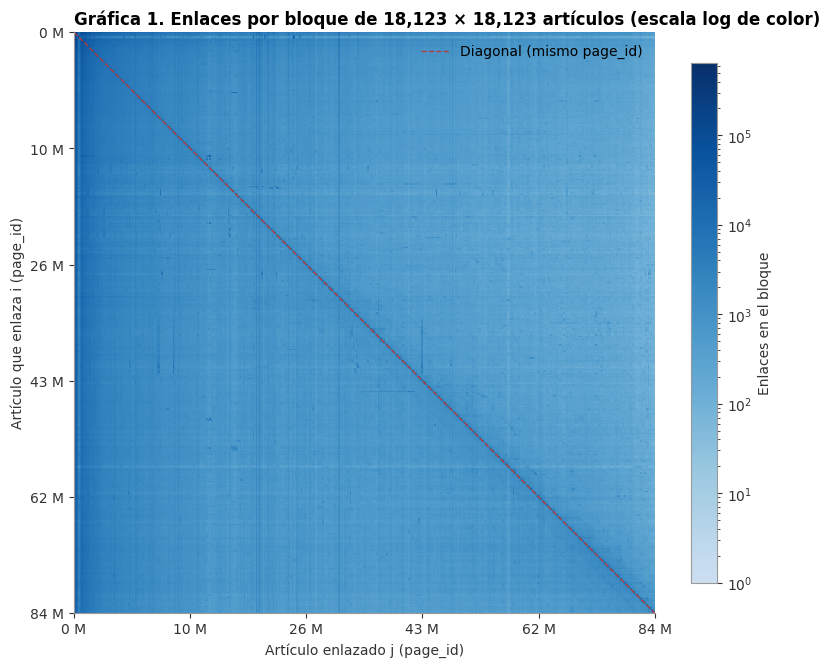

Enlaces hacia un page_id menor (debajo de la diagonal): 73.01 % | hacia uno mayor: 26.99 %


In [4]:
# Gráfica 1. Patrón de la matriz de adyacencia por bloques, con los nodos en orden de page_id
B = 400
tam_bloque = int(np.ceil(n / B))
conteo = np.bincount((origen // tam_bloque).astype(np.int64) * B + destino // tam_bloque, minlength=B * B).reshape(B, B)
conteo = conteo.astype(float)
conteo[conteo == 0] = np.nan

fig, ax = plt.subplots(figsize=(8.2, 7))
im = ax.imshow(conteo, cmap=CMAP_SEC, norm=LogNorm(vmin=1, vmax=np.nanmax(conteo)), interpolation="nearest",
               extent=(0, n, n, 0))
ax.plot([0, n], [0, n], color=ROJO, linewidth=1, linestyle="--", label="Diagonal (mismo page_id)")
marcas = np.linspace(0, n - 1, 6).astype(int)
ax.set_xticks(marcas, labels=[f"{ids[i] / 1e6:.0f} M" for i in marcas])
ax.set_yticks(marcas, labels=[f"{ids[i] / 1e6:.0f} M" for i in marcas])
estilo_ejes(ax, f"Gráfica 1. Enlaces por bloque de {tam_bloque:,} × {tam_bloque:,} artículos (escala log de color)",
            "Artículo enlazado j (page_id)", "Artículo que enlaza i (page_id)", rejilla=None)
fig.colorbar(im, ax=ax, label="Enlaces en el bloque", shrink=0.82)
ax.legend(loc="upper right")
plt.tight_layout()
archivo_g1 = reg.guardar_figura(fig, "grafica_01_patron_matriz", NB)
plt.show()

abajo = (destino < origen).mean()
print(f"Enlaces hacia un page_id menor (debajo de la diagonal): {pct(abajo)} | hacia uno mayor: {pct(1 - abajo)}")
del conteo

In [5]:
# Guardado de A en .npz con el mapeo índice → page_id, en el formato que lee scipy.sparse.load_npz
t0 = time.perf_counter()
np.savez_compressed(ARCHIVO_MATRIZ, data=A.data, indices=A.indices, indptr=A.indptr, format=np.bytes_("csr"),
                    shape=np.array(A.shape), ids=ids)
A_leida = sp.load_npz(ARCHIVO_MATRIZ)
assert A_leida.shape == A.shape and np.array_equal(A_leida.indptr, A.indptr) and np.array_equal(A_leida.indices, A.indices)
assert np.array_equal(np.load(ARCHIVO_MATRIZ)["ids"], ids)
print(f"{ARCHIVO_MATRIZ.name}: {tamano(ARCHIVO_MATRIZ.stat().st_size)} en {time.perf_counter() - t0:.0f} s | "
      f"matriz {A_leida.shape}, nnz = {A_leida.nnz:,}")
del A_leida, origen, destino
reg.registrar_paso("02.2", inicio, [reg.guardar_tabla(memoria, "02_memoria_matriz", NB), archivo_g1, ARCHIVO_MATRIZ],
                   f"nnz = {A.nnz:,}; {pct(abajo)} de los enlaces hacia un page_id menor")

adyacencia.npz: 720.2 MB en 79 s | matriz (7249099, 7249099), nnz = 236,242,098


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · REPRESENTACIÓN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. Matriz de transición</span></div>


PageRank modela a un **lector aleatorio** que está en un artículo y sigue uno de sus enlaces al azar. Su distribución
de probabilidad $v$ sobre los artículos evoluciona como $v' = M v$, donde $M$ es la **matriz de transición**
estocástica **por columnas** (Leskovec, Rajaraman y Ullman, *Mining of Massive Datasets*, cap. 5):

$$M_{ji} = \begin{cases} 1 / k_{out}(i) & \text{si } i \to j, \\ 0 & \text{en otro caso,} \end{cases}
\qquad\text{es decir,}\qquad M = A^\top D_{out}^{-1}.$$

**No se construye $M$.** Basta con $M v = A^\top (v \oslash k_{out})$: se divide $v$ entre los grados de salida y se
multiplica por $A^\top$. Así solo se guarda $A^\top$, que tiene el mismo patrón que $A$.

**Producto en paralelo.** El producto matriz-vector de `scipy.sparse` usa un solo núcleo: con 236 M entradas tarda
~1.3 s. Como cada fila del resultado depende solo de su fila de la matriz, $A^\top$ se divide en **16 bloques de
filas** y se multiplican en paralelo con hilos (`scipy` libera el GIL durante el producto). Así baja a ~0.7 s, y el
resultado es idéntico al del producto sin dividir.

Los dos obstáculos clásicos:

- **Nodos colgantes** ($k_{out} = 0$): su columna de $M$ es cero y la probabilidad que llega a ellos se pierde.
- **Trampas de araña:** grupos de nodos sin enlaces hacia fuera, que acumulan toda la probabilidad. En términos de
  grafos, son las **componentes fuertemente conexas (SCC) sin salida** con más de un nodo.

In [6]:
# Producto por bloques de filas en paralelo y matriz Aᵀ dividida en bloques
inicio = time.time()
BLOQUES = 16
POOL = ThreadPoolExecutor(BLOQUES)


def partir(X, bloques=BLOQUES):
    """
    Divide una matriz CSR en bloques consecutivos de filas.

    Parámetros
    ----------
    X : scipy.sparse.csr_matrix
        Matriz a dividir.
    bloques : int
        Número de bloques.

    Retorna
    -------
    list of scipy.sparse.csr_matrix
        Bloques de filas, en orden.
    """
    cortes = np.linspace(0, X.shape[0], bloques + 1).astype(int)
    return [X[a:b] for a, b in zip(cortes[:-1], cortes[1:])]


def producto(bloques, x):
    """
    Calcula X @ x multiplicando en paralelo los bloques de filas de X.

    Parámetros
    ----------
    bloques : list of scipy.sparse.csr_matrix
        Bloques de filas de X (salida de `partir`).
    x : np.ndarray
        Vector (n,) o matriz densa (n, K).

    Retorna
    -------
    np.ndarray
        El producto, con las filas en el orden original.
    """
    return np.concatenate(list(POOL.map(lambda bloque: bloque @ x, bloques)))


AT_bloques = partir(A.T.tocsr())
x = np.random.default_rng(42).random(n)
t0 = time.perf_counter(); y_simple = A.T @ x; t_simple = time.perf_counter() - t0
t0 = time.perf_counter(); y_bloques = producto(AT_bloques, x); t_bloques = time.perf_counter() - t0
assert np.allclose(y_simple, y_bloques, rtol=1e-12, atol=0)
print(f"Aᵀx: {t_simple:.2f} s con un núcleo | {t_bloques:.2f} s con {BLOQUES} bloques en paralelo | mismo resultado")
del x, y_simple, y_bloques

Aᵀx: 1.23 s con un núcleo | 0.58 s con 16 bloques en paralelo | mismo resultado


In [7]:
# Columnas de M, nodos colgantes y fuga de probabilidad sin teletransportación
inv_k_out = np.divide(1.0, k_out, out=np.zeros(n), where=k_out > 0)
colgantes = k_out == 0
print(f"Columnas de M que suman 1: {(~colgantes).sum():,} | que suman 0 (colgantes): {colgantes.sum():,}")

v = np.full(n, 1 / n)
masa = [v.sum()]
for _ in range(30):
    v = producto(AT_bloques, v * inv_k_out)
    masa.append(v.sum())
print("Probabilidad total tras t pasos de v' = Mv, sin teletransportación:")
print(" | ".join(f"t = {t}: {masa[t]:.4f}" for t in [0, 1, 2, 5, 10, 20, 30]))
tabla_fuga = pd.DataFrame({"probabilidad total": masa}).rename_axis("t")

# Eliminación recursiva de colgantes: al quitar un colgante, quienes solo lo enlazaban a él se vuelven colgantes
vivo = np.ones(n, dtype=bool)
k_vivo = k_out.astype(np.int64)
rondas = []
while True:
    quitar = vivo & (k_vivo == 0)
    if not quitar.any():
        break
    vivo[quitar] = False
    rondas.append(int(quitar.sum()))
    k_vivo = k_vivo - np.rint(A @ quitar.astype(float)).astype(np.int64)
print(f"Eliminación recursiva de colgantes: {len(rondas)} rondas, se quitan {(~vivo).sum():,} nodos "
      f"({pct((~vivo).mean(), 3)}) | por ronda: {rondas}")
del v, k_vivo

Columnas de M que suman 1: 7,241,465 | que suman 0 (colgantes): 7,634


Probabilidad total tras t pasos de v' = Mv, sin teletransportación:
t = 0: 1.0000 | t = 1: 0.9989 | t = 2: 0.9981 | t = 5: 0.9977 | t = 10: 0.9972 | t = 20: 0.9962 | t = 30: 0.9952


Eliminación recursiva de colgantes: 2 rondas, se quitan 7,658 nodos (0.106 %) | por ronda: [7634, 24]


In [8]:
# SCC, trampas de araña y estructura de corbata (Broder et al., 2000)
t0 = time.perf_counter()
n_scc, scc = connected_components(A, directed=True, connection="strong")
segundos_scc = time.perf_counter() - t0
tam_scc = np.bincount(scc)
mayor = tam_scc.argmax()

# Una SCC tiene salida si alguna arista va de ella a otra SCC
filas = np.repeat(np.arange(n, dtype=np.int32), np.diff(A.indptr))
scc_origen, scc_destino = scc[filas], scc[A.indices]
tiene_salida = np.zeros(n_scc, dtype=bool)
tiene_salida[np.unique(scc_origen[scc_origen != scc_destino])] = True
del filas, scc_origen, scc_destino
sin_salida = ~tiene_salida
trampas = np.where(sin_salida & (tam_scc > 1))[0]

# IN: llegan a la SCC mayor; OUT: se alcanzan desde ella (BFS hacia adelante en A y hacia atrás en Aᵀ)
semilla = np.where(scc == mayor)[0][0]
alcanzables = np.zeros(n, dtype=bool)
alcanzables[breadth_first_order(A, semilla, directed=True, return_predecessors=False)] = True
llegan = np.zeros(n, dtype=bool)
llegan[breadth_first_order(A.T.tocsr(), semilla, directed=True, return_predecessors=False)] = True
en_scc = scc == mayor
corbata = pd.Series({
    "SCC mayor (núcleo)": en_scc.sum(),
    "IN (llegan al núcleo, no se alcanzan desde él)": (llegan & ~en_scc).sum(),
    "OUT (se alcanzan desde el núcleo, no llegan a él)": (alcanzables & ~en_scc).sum(),
    "Resto (tentáculos, tubos y desconectados)": (~llegan & ~alcanzables).sum(),
}, name="artículos").to_frame()
corbata["%"] = corbata["artículos"].map(lambda x: pct(x / n))
corbata["artículos"] = corbata["artículos"].map("{:,}".format)
print(f"SCC: {n_scc:,} componentes en {segundos_scc:.0f} s | sin salida: {sin_salida.sum():,} "
      f"(de un nodo = colgantes: {(sin_salida & (tam_scc == 1)).sum():,}; trampas de más de un nodo: {len(trampas)})")
display(corbata)

tabla_trampas = pd.DataFrame([{"trampa": t, "artículos": " ↔ ".join(nodos.loc[scc == t, "title"]),
                               "k_in de cada uno": nodos.loc[scc == t, "grado_entrada"].tolist()} for t in trampas])
print("Las trampas de araña:")
display(tabla_trampas.set_index("trampa"))
reg.registrar_paso("02.3", inicio, [
    reg.guardar_tabla(tabla_fuga, "03_fuga_probabilidad", NB),
    reg.guardar_tabla(pd.DataFrame({"colgantes quitados": rondas}).rename_axis("ronda"), "03_rondas_colgantes", NB),
    reg.guardar_tabla(corbata, "03_corbata", NB), reg.guardar_tabla(tabla_trampas, "03_trampas", NB),
], f"{colgantes.sum():,} colgantes; SCC mayor {pct(tam_scc.max() / n)}; {len(trampas)} trampas de araña")

SCC: 567,981 componentes en 7 s | sin salida: 7,642 (de un nodo = colgantes: 7,634; trampas de más de un nodo: 8)


,artículos,%
SCC mayor (núcleo),"6,654,680",91.80 %
"IN (llegan al núcleo, no se alcanzan desde él)","586,745",8.09 %
"OUT (se alcanzan desde el núcleo, no llegan a él)","4,691",0.06 %
"Resto (tentáculos, tubos y desconectados)","2,983",0.04 %


Las trampas de araña:


,artículos,k_in de cada uno
trampa,,
702,Physophora hydrostatica ↔ Physophora,"[4, 4]"
2456,Pierre Verdrager ↔ L'enfant interdit,"[2, 1]"
2636,Badr Lama ↔ The Beautiful Bedouin,"[4, 1]"
3490,Crozier (surname) ↔ Crosier (surname),"[4, 2]"
3588,World lexicon of Tolnai ↔ New world lexicon of Tolnai,"[4, 3]"
3897,Ashiyane ↔ Behrooz Kamalian,"[2, 2]"
4419,Shackel ↔ Shackell,"[3, 1]"
64988,Masnik ↔ Masnick,"[1, 1]"


**Observaciones y decisión: matriz de transición**

- **La matriz (sección 2).** $A$ es de **7,249,099 × 7,249,099** con **236,242,098** entradas distintas de cero, una
  densidad de **4.50e-06**. En CSR ocupa **2.86 GB**, contra **420 TB** de la versión densa: **146,791 veces** menos.
  El producto $A^\top x$ baja de **1.23 s** con un núcleo a **0.58 s** con 16 bloques en paralelo.
- **Los enlaces van sobre todo hacia el pasado, pero no solo (Gráfica 1).** El **73.01 %** apunta a un `page_id`
  menor. En cit-HepPh era el 99.52 %, porque una cita casi nunca apunta al futuro; un artículo de Wikipedia, en
  cambio, se sigue editando y enlaza a páginas creadas después. La banda vertical oscura de la izquierda son los
  `page_id` más bajos, que reciben enlaces de todo el archivo.
- **Casi no hay colgantes.** Son **7,634** (**0.11 %**). Sin teletransportación la probabilidad total apenas baja:
  **0.9989** tras un paso y **0.9952** tras 30. En cit-HepPh se perdía el 77 % en 5 pasos.
- **La eliminación recursiva sí sería viable:** bastan **2** rondas, que quitan **7,658** nodos (**0.106 %**), contra
  19 rondas y el 28 % en cit-HepPh. Wikipedia tiene muchos ciclos, así que quitar un colgante casi nunca crea otro.
  Aun así se mantiene el tratamiento estándar (repartir su masa según $v$) para no excluir artículos.
- **Solo hay 8 trampas de araña, todas de 2 nodos.** Son pares que solo se enlazan entre sí: variantes de un
  apellido (*Masnik* ↔ *Masnick*, *Shackel* ↔ *Shackell*), un género y su única especie (*Physophora*), un libro y
  su versión nueva. Tienen a lo más 4 enlaces de entrada cada uno, así que la teletransportación basta.
- **Estructura de corbata.** El núcleo (la SCC mayor) tiene el **91.80 %** de los artículos (**6,654,680**). IN tiene
  el **8.09 %** (**586,745**): artículos que enlazan al núcleo, pero a los que nadie del núcleo enlaza, típicamente
  huérfanos o recién creados. OUT tiene el **0.06 %** y el resto el **0.04 %**. Es un grafo mucho más conexo que la
  Web de Broder *et al.* (2000), cuyo núcleo era ~28 %.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · REPRESENTACIÓN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3.1 Grafo de análisis: sin páginas de desambiguación</span></div>


**Decisión.** El análisis principal (PageRank, HITS y el PageRank sensible a tópico del notebook 3) se hace sobre el
grafo **sin las páginas de desambiguación**. Se quitan los nodos y todas sus aristas, de entrada y de salida.

**Por qué.** Una página de desambiguación (*Mercury*, *Aberdeen (disambiguation)*) no es contenido: es un menú que
enlaza a todos los artículos con un nombre parecido. Cumple el mismo papel que los seudoartistas (`Traditional`) en
la red de Spotify: conecta artículos sin relación entre sí y crea hubs artificiales. Los enlaces que *reciben* suelen
ser errores de edición que los bots corrigen.

Las **listas** y las **páginas de año** sí son contenido y se conservan. Se siguen con las marcas `es_lista` y
`es_cronologia`. El grafo completo se compara en la sección de robustez (6.2).

In [9]:
# Grafo de análisis: subgrafo inducido por los artículos que no son de desambiguación
inicio = time.time()
conserva = ~nodos["is_disambig"].to_numpy()
de_desamb = int(A[~conserva].nnz)
a_desamb = int(k_in[~conserva].sum())

A_an = A[conserva][:, conserva].tocsr()
nodos_an = nodos[conserva].reset_index(drop=True)
nodos_an.index.name = "indice"
n_an = len(nodos_an)
k_out_an = np.asarray(A_an.sum(axis=1)).ravel()
k_in_an = np.asarray(A_an.sum(axis=0)).ravel()
nodos_an["k_out"], nodos_an["k_in"] = k_out_an, k_in_an
n_scc_an, scc_an = connected_components(A_an, directed=True, connection="strong")

comparacion_grafos = pd.DataFrame({
    "completo": [f"{n:,}", f"{A.nnz:,}", f"{(k_out == 0).sum():,}", pct(tam_scc.max() / n)],
    "análisis (sin desambiguación)": [f"{n_an:,}", f"{A_an.nnz:,}", f"{(k_out_an == 0).sum():,}",
                                       pct(np.bincount(scc_an).max() / n_an)],
}, index=["nodos", "aristas", "nodos colgantes", "SCC mayor (% de nodos)"])
display(comparacion_grafos)
print(f"Aristas quitadas: {A.nnz - A_an.nnz:,} | que salen de desambiguaciones: {de_desamb:,} | "
      f"que llegan a ellas: {a_desamb:,}")
print("Desambiguaciones con más enlaces de entrada (enlaces que deberían apuntar a un artículo concreto):")
top_desamb = nodos.loc[~conserva].nlargest(10, "grado_entrada")[["id", "title", "grado_entrada", "grado_salida"]]
display(top_desamb.head(5))

inv_k_out_an = np.divide(1.0, k_out_an, out=np.zeros(n_an), where=k_out_an > 0)
AT_an_bloques = partir(A_an.T.tocsr())
A_an_bloques = partir(A_an)
del A   # para la robustez (6.2) basta con AT_bloques
reg.registrar_paso("02.3.1", inicio, [reg.guardar_tabla(comparacion_grafos, "03_1_comparacion_grafos", NB),
                                      reg.guardar_tabla(top_desamb.set_index("id"), "03_1_desambiguaciones_mas_enlazadas", NB)],
                   f"{n_an:,} nodos y {A_an.nnz:,} aristas")

,completo,análisis (sin desambiguación)
nodos,"7,249,099","6,879,374"
aristas,"236,242,098","233,221,445"
nodos colgantes,"7,634","7,557"
SCC mayor (% de nodos),91.80 %,94.70 %


Aristas quitadas: 3,020,653 | que salen de desambiguaciones: 2,907,694 | que llegan a ellas: 277,405
Desambiguaciones con más enlaces de entrada (enlaces que deberían apuntar a un artículo concreto):


,id,title,grado_entrada,grado_salida
indice,,,,
134315,290282,State,457,77
2232966,18573408,List of the oldest buildings in Massachusetts,143,216
11617,23813,Pope Stephen II,136,57
2943313,26181056,And,119,27
11031,22622,Orthodox,109,33


**Observaciones: grafo de análisis**

- **Qué se quita.** Las **369,725** páginas de desambiguación (**5.10 %** de los artículos) con sus **3,020,653**
  aristas (**1.28 %**). De ellas, **2,907,694** salen de las desambiguaciones y solo **277,405** llegan a ellas.
- **El grafo de análisis.** Tiene **6,879,374** artículos y **233,221,445** enlaces. La SCC mayor sube del **91.80 %**
  al **94.70 %**: las desambiguaciones casi no reciben enlaces, así que estaban fuera del núcleo.
- **Enlaces que deberían apuntar a otro lado.** Las desambiguaciones más enlazadas son *State* (**457**),
  *Pope Stephen II*, *And* y *Orthodox*: enlaces que un editor dejó a medias. *List of the oldest buildings in
  Massachusetts* aparece como desambiguación, pero es un **falso positivo residual**: lleva la plantilla de
  mantenimiento `{{Split and dab}}` (una propuesta de dividirla y convertirla en desambiguación), que la expresión
  toma por una de desambiguación. Son casos aislados que no cambian el análisis.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · PAGERANK</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. PageRank</span></div>


**Grafo.** Toda esta sección usa el grafo de análisis (3.1).

**Qué calcula.** PageRank es el vector estacionario del paseo aleatorio con teletransportación:

$$r = \beta M r + (1 - \beta)\, v, \qquad \sum_i r_i = 1,$$

con $v = e/n$ (salto uniforme). $\beta$ es la probabilidad de seguir un enlace y $1 - \beta$ la de saltar a un
artículo al azar.

**Nodos colgantes.** La probabilidad que llega a un colgante se reparte también según $v$, como hace
`nx.pagerank` con `dangling=None`. En cada paso se calcula $r' = \beta M r$, cuya suma es $\beta$ menos la masa
de los colgantes, y se agrega lo que falta para sumar 1, repartido según $v$:

$$r' \leftarrow \beta M r + \big(1 - \lVert \beta M r \rVert_1\big)\, v.$$

**Método de potencias.** Se parte de $r_0 = e/n$ y se itera hasta que $\lVert r_{t+1} - r_t \rVert_1 < 10^{-10}$, con un
máximo de 1,000 iteraciones.

In [10]:
# PageRank por el método de potencias sobre la matriz dispersa
inicio = time.time()
TOL = 1e-10
BETAS = [0.70, 0.85, 0.95]


def pagerank_potencia(AT_bloques, inv_k_out, v=None, beta=0.85, tol=TOL, max_iter=1000):
    """
    Calcula PageRank por el método de potencias, con los colgantes repartidos según v.

    Parámetros
    ----------
    AT_bloques : list of scipy.sparse.csr_matrix
        Bloques de filas de Aᵀ (salida de `partir`).
    inv_k_out : np.ndarray
        1 / k_out para cada nodo; 0 en los colgantes.
    v : np.ndarray, opcional
        Vector de teletransportación (no negativo); se normaliza a suma 1. Si es None, uniforme.
    beta : float
        Probabilidad de seguir un enlace.
    tol : float
        Criterio de paro sobre ‖r_{t+1} − r_t‖₁.
    max_iter : int
        Número máximo de iteraciones.

    Retorna
    -------
    tuple of (np.ndarray, int)
        Vector de PageRank (suma 1) e iteraciones hasta converger. Si no converge, devuelve el último vector y
        max_iter, y anota el residuo final en RESUMEN.md.
    """
    n = len(inv_k_out)
    v = np.full(n, 1 / n) if v is None else v / v.sum()
    r = np.full(n, 1 / n)
    for iteracion in range(1, max_iter + 1):
        nuevo = beta * producto(AT_bloques, r * inv_k_out)
        nuevo += (1 - nuevo.sum()) * v
        error = np.abs(nuevo - r).sum()
        r = nuevo
        if error < tol:
            return r, iteracion
    reg.nota(f"PageRank (β = {beta}) no convergió en {max_iter} iteraciones; residuo final ‖r_t+1 − r_t‖₁ = {error:.2e}")
    return r, max_iter


pr, filas_pr = {}, []
for beta in BETAS:
    t0 = time.perf_counter()
    pr[beta], iteraciones = pagerank_potencia(AT_an_bloques, inv_k_out_an, beta=beta)
    segundos = time.perf_counter() - t0
    filas_pr.append({"β": beta, "iteraciones": iteraciones, "segundos": round(segundos), "suma": round(pr[beta].sum(), 10),
                     "máximo": pr[beta].max(), "mínimo": pr[beta].min(),
                     "máximo / mínimo": round(pr[beta].max() / pr[beta].min()),
                     "top 1": nodos_an.loc[pr[beta].argmax(), "title"]})
display(pd.DataFrame(filas_pr).set_index("β"))
pr85 = pr[0.85]

,iteraciones,segundos,suma,máximo,mínimo,máximo / mínimo,top 1
β,,,,,,,
0.70,42,28,1.0,0.000853,4.366709e-08,19525,Association football
0.85,70,46,1.0,0.000934,2.184883e-08,42769,United States
0.95,163,108,1.0,0.001037,7.294736e-09,142222,United States


**Validación de la implementación.** Se comprueba de dos formas:

1. **Punto fijo en el grafo completo.** El vector debe cumplir la ecuación de PageRank: se aplica una iteración más
   y se mide cuánto cambia.
2. **Contra `networkx` en un subgrafo.** `nx.pagerank` no cabe con 7 M de nodos, así que se compara en el subgrafo
   inducido por los 20,000 artículos con más enlaces de entrada, con el mismo β y tolerancias estrictas.

In [11]:
# Validación: residuo del punto fijo y comparación con networkx en un subgrafo
siguiente = 0.85 * producto(AT_an_bloques, pr85 * inv_k_out_an)
siguiente += (1 - siguiente.sum()) / n_an
residuo = np.abs(siguiente - pr85).sum()
del siguiente

SUB = np.sort(np.argsort(-k_in_an)[:20_000])
A_sub = A_an[SUB][:, SUB].tocsr()
k_sub = np.asarray(A_sub.sum(axis=1)).ravel()
inv_sub = np.divide(1.0, k_sub, out=np.zeros(len(SUB)), where=k_sub > 0)
pr_sub, _ = pagerank_potencia(partir(A_sub.T.tocsr(), 1), inv_sub, beta=0.85, tol=1e-13)
pr_nx = nx.pagerank(nx.from_scipy_sparse_array(A_sub, create_using=nx.DiGraph), alpha=0.85, tol=1e-14, max_iter=10_000)
pr_nx = np.array([pr_nx[i] for i in range(len(SUB))])
diferencia = np.abs(pr_sub - pr_nx).max()
tabla_validacion = pd.Series({"residuo del punto fijo (grafo de análisis)": residuo, "nodos del subgrafo": len(SUB),
                              "aristas del subgrafo": A_sub.nnz, "diferencia máxima con nx.pagerank": diferencia},
                             name="valor").to_frame()
if residuo > 1e-9 or diferencia > 1e-9:
    reg.nota(f"Validación de PageRank fuera de tolerancia: residuo {residuo:.2e}, diferencia con networkx {diferencia:.2e}")

print(f"Residuo del punto fijo ‖r − (βMr + …)‖₁ en el grafo de análisis: {residuo:.2e}")
print(f"Subgrafo de {len(SUB):,} nodos y {A_sub.nnz:,} aristas: diferencia máxima con nx.pagerank = {diferencia:.2e} "
      f"(PageRank máximo del subgrafo {pr_sub.max():.2e})")

Residuo del punto fijo ‖r − (βMr + …)‖₁ en el grafo de análisis: 6.51e-11
Subgrafo de 20,000 nodos y 1,527,547 aristas: diferencia máxima con nx.pagerank = 6.73e-13 (PageRank máximo del subgrafo 3.06e-03)


In [12]:
# Top 20 de PageRank con β = 0.85, junto a su lugar por número de enlaces recibidos
lugar_kin = pd.Series(k_in_an).rank(ascending=False, method="min").astype(int).to_numpy()


def tabla_top(puntaje, k=20, nombre="PageRank"):
    """
    Arma la tabla de los k artículos con mayor puntaje, con sus grados y su lugar por grado de entrada.

    Parámetros
    ----------
    puntaje : np.ndarray
        Puntaje por índice de nodo del grafo de análisis.
    k : int
        Número de artículos.
    nombre : str
        Nombre de la columna del puntaje.

    Retorna
    -------
    pd.DataFrame
        Título, grados, marcas, puntaje y lugar por k_in.
    """
    top = np.argsort(-puntaje)[:k]
    return pd.DataFrame({
        "artículo": nodos_an.loc[top, "title"].to_numpy(), "k_in": k_in_an[top], "k_out": k_out_an[top],
        "lista / cronología": np.where(nodos_an.loc[top, "es_lista"], "lista",
                                       np.where(nodos_an.loc[top, "es_cronologia"], "cronología", "")),
        nombre: puntaje[top], "lugar por k_in": lugar_kin[top],
    }, index=pd.RangeIndex(1, k + 1, name="lugar"))


top20_pr = tabla_top(pr85)
display(top20_pr.style.format({"PageRank": "{:.3e}", "k_in": "{:,}", "k_out": "{:,}", "lugar por k_in": "{:,}"}))
vectores_pr = pd.DataFrame({"id": nodos_an["id"], "title": nodos_an["title"]} |
                           {f"pagerank_{beta:.2f}": pr[beta] for beta in BETAS})
reg.registrar_paso("02.4", inicio, [
    reg.guardar_parquet(vectores_pr, "04_pagerank", NB),
    reg.guardar_tabla(pd.DataFrame(filas_pr).set_index("β"), "04_pagerank_por_beta", NB),
    reg.guardar_tabla(tabla_validacion, "04_validacion", NB), reg.guardar_tabla(top20_pr, "04_top20_pagerank", NB),
], " | ".join(f"β = {f['β']}: {f['iteraciones']} it" for f in filas_pr) + f" | dif. con networkx {diferencia:.1e}")

,artículo,k_in,k_out,lista / cronología,PageRank,lugar por k_in
lugar,,,,,,
1,United States,"218,342.0","1,602.0",,9.345e-04,3
2,The New York Times,"203,648.0",611.0,,8.835e-04,4
3,World War II,"221,247.0",956.0,,8.505e-04,2
4,Association football,"264,742.0",332.0,,7.402e-04,1
5,France,"141,560.0","1,194.0",,5.967e-04,6
6,United Kingdom,"101,389.0","1,405.0",,5.370e-04,13
7,New York City,"149,389.0","1,321.0",,5.254e-04,5
8,The Guardian,"112,739.0",636.0,,4.773e-04,10
9,Germany,"107,148.0",943.0,,4.765e-04,11


**Observaciones: PageRank**

- **Convergencia.** Con $\lVert r_{t+1} - r_t \rVert_1 < 10^{-10}$, PageRank converge en **42**, **70** y **163**
  iteraciones (**28**, **46** y **108** s) para $\beta$ = 0.70, 0.85 y 0.95. Es más rápido que la cota $\beta^t$
  (con $\beta$ = 0.85 haría falta del orden de 140), porque el segundo valor propio de la matriz de Google es menor
  que $\beta$. Los vectores suman **1.0**.
- **Validación.** El residuo del punto fijo es **6.51e-11** y la diferencia máxima con `nx.pagerank` en el subgrafo
  de **20,000** nodos y **1,527,547** aristas es **6.73e-13**, con puntajes del orden de 1e-3: la implementación es
  correcta.
- **Concentración.** El cociente entre el puntaje máximo y el mínimo es **19,525**, **42,769** y **142,222**: con un
  $\beta$ mayor se teletransporta menos y la probabilidad se concentra más.
- **Quiénes están arriba.** Con $\beta$ = 0.85: *United States*, *The New York Times*, *World War II*,
  *Association football*, *France*, *United Kingdom*, *New York City* y *The Guardian*. Son países, ciudades,
  guerras y **fuentes de referencia**. *The Guardian* (8.º), *Oxford University Press* (17.º) y *Latin* (20.º) están
  arriba porque las referencias bibliográficas de Wikipedia enlazan a la publicación (`|work=[[The New York Times]]`).
  *Moth* (18.º) recibe **81,532** enlaces de los miles de artículos breves de especies de polillas.
- **El primer lugar depende de β.** Con 0.70 es *Association football*, el artículo con más enlaces de entrada
  (**264,742**). Con 0.85 y 0.95 es *United States*.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · PAGERANK</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4.1 Sensibilidad a β</span></div>


Se compara qué tanto cambia el ranking entre los tres valores de $\beta$ con dos tipos de medida:

- **Traslape del top-k:** el índice de Jaccard $|T_a \cap T_b| / |T_a \cup T_b|$ entre los $k$ primeros de cada
  ranking. Mide la estabilidad de "los más importantes".
- **Correlación de rangos** sobre los 6.8 M de nodos: la $\tau$ de Kendall y la $\rho$ de Spearman. Miden la
  estabilidad del ranking completo.

,Jaccard top-20,Jaccard top-100,"Jaccard top-1,000",Spearman ρ,Kendall τ
par de β,,,,,
0.70 vs 0.85,0.667,0.724,0.807,0.9913,0.9237
0.85 vs 0.95,0.818,0.681,0.778,0.9887,0.9119
0.70 vs 0.95,0.600,0.481,0.625,0.9621,0.8379


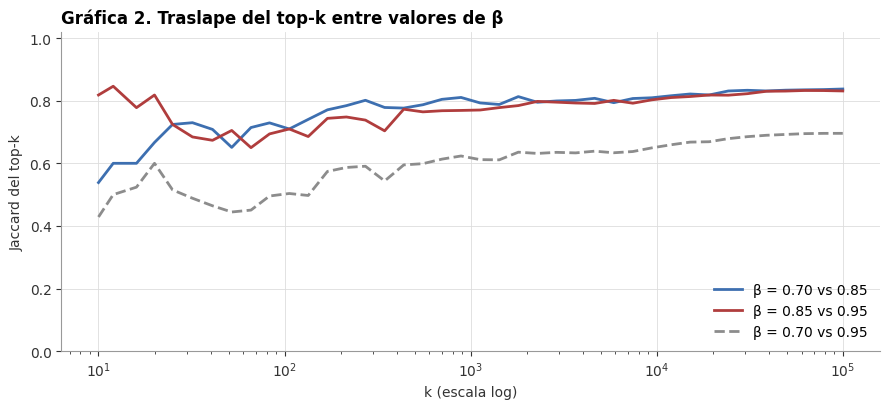

In [13]:
# Jaccard del top-k y correlaciones de Kendall y Spearman entre pares de β
inicio = time.time()
def jaccard_top(a, b, k):
    """
    Índice de Jaccard entre los k nodos con mayor puntaje de dos rankings.

    Parámetros
    ----------
    a, b : np.ndarray
        Puntajes por índice de nodo.
    k : int
        Tamaño del top.

    Retorna
    -------
    float
        |top_a ∩ top_b| / |top_a ∪ top_b|.
    """
    ta, tb = np.argpartition(-a, k)[:k], np.argpartition(-b, k)[:k]
    comun = len(np.intersect1d(ta, tb))
    return comun / (2 * k - comun)


pares = [(0.70, 0.85), (0.85, 0.95), (0.70, 0.95)]
sensibilidad = pd.DataFrame([{
    "par de β": f"{a:.2f} vs {b:.2f}",
    "Jaccard top-20": round(jaccard_top(pr[a], pr[b], 20), 3),
    "Jaccard top-100": round(jaccard_top(pr[a], pr[b], 100), 3),
    "Jaccard top-1,000": round(jaccard_top(pr[a], pr[b], 1000), 3),
    "Spearman ρ": round(spearmanr(pr[a], pr[b]).statistic, 4),
    "Kendall τ": round(kendalltau(pr[a], pr[b]).statistic, 4),
} for a, b in pares]).set_index("par de β")
display(sensibilidad)

# Gráfica 2. Traslape del top-k en función de k
ks = np.unique(np.logspace(1, 5, 40).astype(int))
fig, ax = plt.subplots(figsize=(9, 4.2))
for (a, b), color, estilo in zip(pares, [AZUL, ROJO, GRIS], ["-", "-", "--"]):
    ax.plot(ks, [jaccard_top(pr[a], pr[b], k) for k in ks], color=color, linestyle=estilo, linewidth=2,
            label=f"β = {a:.2f} vs {b:.2f}")
ax.set_xscale("log")
ax.set_ylim(0, 1.02)
estilo_ejes(ax, "Gráfica 2. Traslape del top-k entre valores de β", "k (escala log)", "Jaccard del top-k", rejilla="both")
ax.legend(loc="lower right")
plt.tight_layout()
reg.registrar_paso("02.4.1", inicio, [reg.guardar_tabla(sensibilidad, "04_1_sensibilidad_beta", NB),
                                      reg.guardar_figura(fig, "grafica_02_jaccard_beta", NB)])
plt.show()

**Observaciones: sensibilidad a β**

- **El ranking completo es estable:** Spearman $\rho \ge$ **0.9621** y Kendall $\tau$ entre **0.8379** y **0.9237**.
  Es algo menos estable que en cit-HepPh ($\rho \ge$ 0.9987). Con 6.9 M de artículos hay muchísimos puntajes casi
  empatados en la cola, y cualquier cambio de $\beta$ los reordena.
- **El top-k se mueve más.** El Jaccard del top-100 es **0.724** (0.70 contra 0.85), **0.681** (0.85 contra 0.95) y
  **0.481** (0.70 contra 0.95). En la Gráfica 2 el traslape es más bajo entre $k$ = 100 y 1,000 y se recupera hacia
  $k$ = 10⁵.
- **Por qué.** Con $\beta$ bajo domina la teletransportación y PageRank se parece más al grado de entrada: por eso
  *Association football* queda primero con 0.70. Con $\beta$ alto pesan las cadenas largas de enlaces, que favorecen
  a los artículos enlazados desde artículos importantes (*United States*).
- **Decisión.** Se usa $\beta$ = **0.85**, el valor estándar, como en cit-HepPh y Spotify.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · PAGERANK</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4.2 ¿PageRank es solo contar enlaces?</span></div>


Si PageRank solo contara enlaces, su ranking sería igual al del grado de entrada $k_{in}$. La diferencia es que en
PageRank **un enlace vale lo que vale quien enlaza, dividido entre su número de enlaces**:
$r_j = \beta \sum_{i \to j} r_i / k_{out}(i) + \dots$. Se compara la distribución de los puntajes con la de $k_{in}$
y se buscan los artículos en los que los dos rankings más difieren.

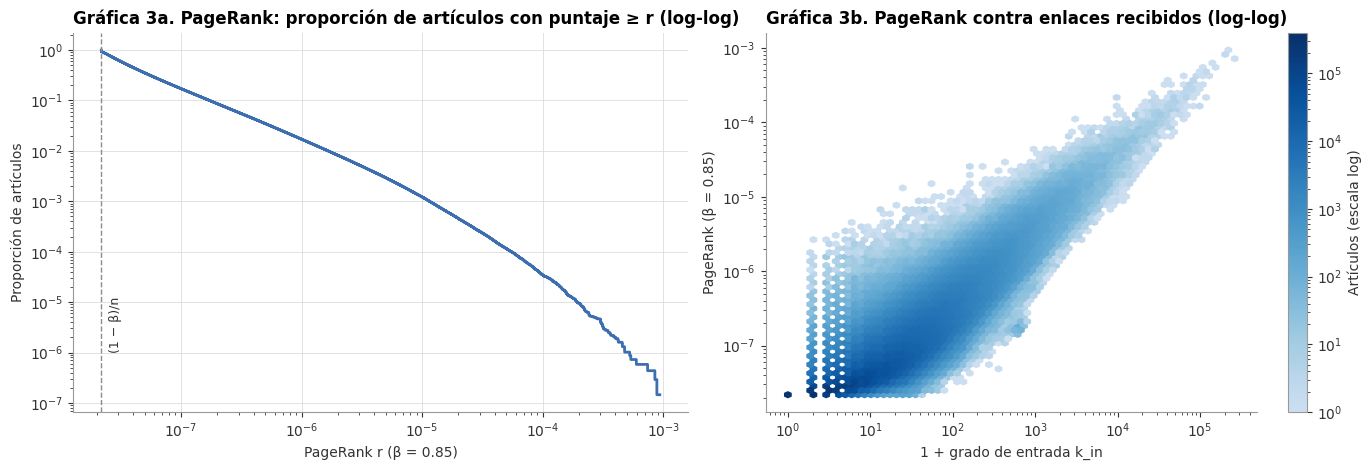

PageRank mínimo: 2.185e-08 | (1 − β)/n = 2.180e-08 | artículos con k_in = 0: 281,500


Spearman ρ(PageRank, k_in) = 0.8622 | Jaccard top-100 PageRank vs k_in = 0.600 | top-20: 0.538


In [14]:
# Gráfica 3. Distribución de PageRank (log-log) y PageRank contra grado de entrada
inicio = time.time()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
ordenado = np.sort(pr85)[::-1]
rangos = np.unique(np.logspace(0, np.log10(n_an), 2000).astype(int)) - 1
ax1.step(ordenado[rangos], (rangos + 1) / n_an, where="post", color=AZUL, linewidth=2)
ax1.axvline((1 - 0.85) / n_an, color=GRIS, linestyle="--", linewidth=1)
ax1.text((1 - 0.85) / n_an * 1.15, 1e-6, "(1 − β)/n", fontsize=9, color=TINTA, rotation=90, va="bottom")
ax1.set_xscale("log")
ax1.set_yscale("log")
estilo_ejes(ax1, "Gráfica 3a. PageRank: proporción de artículos con puntaje ≥ r (log-log)", "PageRank r (β = 0.85)",
            "Proporción de artículos", rejilla="both")

hb = ax2.hexbin(k_in_an + 1, pr85, xscale="log", yscale="log", gridsize=70, bins="log", cmap=CMAP_SEC, mincnt=1)
fig.colorbar(hb, ax=ax2, label="Artículos (escala log)")
estilo_ejes(ax2, "Gráfica 3b. PageRank contra enlaces recibidos (log-log)", "1 + grado de entrada k_in",
            "PageRank (β = 0.85)", rejilla=None)
plt.tight_layout()
archivo_g3 = reg.guardar_figura(fig, "grafica_03_pagerank_vs_kin", NB)
plt.show()

rho_kin = spearmanr(pr85, k_in_an).statistic
print(f"PageRank mínimo: {pr85.min():.3e} | (1 − β)/n = {(1 - 0.85) / n_an:.3e} | "
      f"artículos con k_in = 0: {(k_in_an == 0).sum():,}")
print(f"Spearman ρ(PageRank, k_in) = {rho_kin:.4f} | Jaccard top-100 PageRank vs k_in = "
      f"{jaccard_top(pr85, k_in_an.astype(float), 100):.3f} | top-20: {jaccard_top(pr85, k_in_an.astype(float), 20):.3f}")

In [15]:
# Artículos con mayor diferencia entre su lugar en PageRank y su lugar por enlaces recibidos
lugar_pr = pd.Series(pr85).rank(ascending=False, method="min").astype(int).to_numpy()
comparacion = pd.DataFrame({"artículo": nodos_an["title"], "k_in": k_in_an, "k_out": k_out_an,
                            "lugar PageRank": lugar_pr, "lugar k_in": lugar_kin})
comparacion["suben (lugares)"] = comparacion["lugar k_in"] - comparacion["lugar PageRank"]
top500 = comparacion[comparacion["lugar PageRank"] <= 500]
print("Dentro del top-500 de PageRank, los que más suben respecto a su lugar por k_in:")
suben = top500.nlargest(8, "suben (lugares)")
bajan = comparacion[comparacion["lugar k_in"] <= 500].nsmallest(8, "suben (lugares)")
display(suben)
print("Dentro del top-500 por k_in, los que más bajan en PageRank:")
display(bajan)

# Calidad de quien enlaza: PageRank y k_out medianos de los que enlazan al que más sube y al que más baja
for etiqueta, fila in [("sube", top500["suben (lugares)"].idxmax()),
                       ("baja", comparacion.loc[comparacion["lugar k_in"] <= 500, "suben (lugares)"].idxmin())]:
    enlazan = A_an[:, fila].nonzero()[0]
    print(f"{etiqueta}: {nodos_an.loc[fila, 'title']} | lo enlazan: {len(enlazan):,} | PageRank mediano de quienes lo "
          f"enlazan: {np.median(pr85[enlazan]):.2e} | k_out mediano de quienes lo enlazan: {np.median(k_out_an[enlazan]):.0f}")
print(f"Referencia: PageRank mediano de todo el grafo {np.median(pr85):.2e} | k_out mediano {np.median(k_out_an):.0f}")
reg.registrar_paso("02.4.2", inicio, [archivo_g3, reg.guardar_tabla(suben, "04_2_suben_vs_kin", NB),
                                      reg.guardar_tabla(bajan, "04_2_bajan_vs_kin", NB)],
                   f"Spearman ρ(PageRank, k_in) = {rho_kin:.4f}")

Dentro del top-500 de PageRank, los que más suben respecto a su lugar por k_in:


,artículo,k_in,k_out,lugar PageRank,lugar k_in,suben (lugares)
indice,,,,,,
151909,Open access,2626.0,246.0,436,6677,6241
31611,Broadsheet,2909.0,36.0,220,5804,5584
10268,Oxford English Dictionary,3655.0,193.0,341,4206,3865
1660182,Web of Science,4233.0,71.0,449,3453,3004
12203,Social science,4454.0,411.0,467,3246,2779
1303777,Journal Citation Reports,4489.0,19.0,428,3200,2772
302957,Impact factor,4774.0,77.0,317,2925,2608
9501,Magazine,4874.0,211.0,376,2835,2459


Dentro del top-500 por k_in, los que más bajan en PageRank:


,artículo,k_in,k_out,lugar PageRank,lugar k_in,suben (lugares)
indice,,,,,,
231927,Season (sports),16935.0,242.0,2772,478,-2294
1932159,Review aggregator,16129.0,22.0,2468,497,-1971
610263,Oricon,17814.0,69.0,2171,440,-1731
3881,Drum kit,19384.0,233.0,2099,387,-1712
647251,ARIA Charts,23006.0,154.0,1902,312,-1590
837837,The A.V. Club,18820.0,52.0,1958,405,-1553
575334,Contemporary R&B,16509.0,217.0,1965,491,-1474
1526,Bass guitar,20256.0,107.0,1782,370,-1412


sube: Open access | lo enlazan: 2,626 | PageRank mediano de quienes lo enlazan: 1.21e-07 | k_out mediano de quienes lo enlazan: 22


baja: Season (sports) | lo enlazan: 16,935 | PageRank mediano de quienes lo enlazan: 4.57e-08 | k_out mediano de quienes lo enlazan: 55
Referencia: PageRank mediano de todo el grafo 3.68e-08 | k_out mediano 18


**Observaciones: PageRank contra enlaces recibidos**

- **Arriba se parecen más que en cit-HepPh.** La correlación de rangos es alta (Spearman $\rho$ = **0.8622**) y el
  traslape con el top por enlaces recibidos es de **0.538** en el top-20 y **0.600** en el top-100. En cit-HepPh era
  de 0.081 y 0.212. En Wikipedia los artículos con más enlaces de entrada los reciben de páginas muy variadas, muchas
  de ellas importantes, así que contar enlaces y ponderarlos da resultados parecidos en el top.
- **Distribución (Gráfica 3a).** Tiene una cola pesada. El mínimo (**2.185e-08**) casi coincide con
  $(1-\beta)/n$ = **2.180e-08**: los **281,500** artículos sin enlaces de entrada solo reciben la teletransportación
  y su parte de la masa de los colgantes, que es muy pequeña.
- **Mismos enlaces, puntajes distintos (Gráfica 3b).** Para un mismo $k_{in}$, el PageRank varía más de un orden de
  magnitud. La diferencia está en **quién** enlaza:
  - **Suben** conceptos de la publicación académica y periodística: *Open access* (del lugar **6,677** por enlaces
    recibidos al **436** en PageRank), *Broadsheet*, *Oxford English Dictionary*, *Web of Science*,
    *Journal Citation Reports*, *Impact factor*. Los enlazan los artículos de revistas y periódicos, que a su vez
    son muy enlazados por las referencias. Quienes enlazan a *Open access* tienen un PageRank mediano de
    **1.21e-07**, **3.3 veces** la mediana del grafo (**3.68e-08**).
  - **Bajan** artículos enlazados desde muchísimas páginas periféricas: *Season (sports)* (del lugar **478** al
    **2,772**), *Review aggregator*, *Oricon*, *ARIA Charts*, *The A.V. Club*, *Drum kit*, *Bass guitar*. Los
    enlazan temporadas deportivas, discos y canciones con PageRank mediano de **4.57e-08** y un $k_{out}$ mediano
    de **55** (contra **18** en todo el grafo): cada enlace vale poco.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · HITS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5. HITS: hubs y autoridades</span></div>


**Idea (Kleinberg, 1999).** Cada artículo tiene dos puntajes:

- **Autoridad** $a_j$: es alta si al artículo lo enlazan **buenos hubs**. Es un artículo de referencia.
- **Hub** $h_i$: es alto si el artículo **enlaza a buenas autoridades**. En Wikipedia lo esperable son listas,
  índices y páginas de año, que reúnen muchos artículos importantes.

Los dos se definen uno en función del otro y se iteran con normalización:

$$a \leftarrow A^\top h, \qquad h \leftarrow A\,a, \qquad a \leftarrow a / \lVert a \rVert_1, \quad h \leftarrow h / \lVert h \rVert_1.$$

Al sustituir, $a \propto A^\top A\, a$ y $h \propto A A^\top h$: en el límite, $a$ es el **vector singular derecho
principal** de $A$ y $h$ el izquierdo. La velocidad del método de potencias depende de la brecha: el error se reduce
por un factor $(\sigma_2 / \sigma_1)^2$ en cada iteración.

**Implementación.** Método de potencias propio sobre los bloques de $A$ y $A^\top$, con normalización $L_1$ (como
`nx.hits`), el criterio de paro $\lVert h_{t+1} - h_t \rVert_1 < 10^{-10}$ y un máximo de 500 iteraciones.

In [16]:
# HITS por el método de potencias sobre el grafo de análisis
inicio = time.time()
def hits_potencia(A_bloques, AT_bloques, tol=TOL, max_iter=500):
    """
    Calcula los puntajes de hub y autoridad de HITS por el método de potencias (normalización L1).

    Parámetros
    ----------
    A_bloques, AT_bloques : list of scipy.sparse.csr_matrix
        Bloques de filas de A y de Aᵀ (salida de `partir`).
    tol : float
        Criterio de paro sobre ‖h_{t+1} − h_t‖₁.
    max_iter : int
        Número máximo de iteraciones.

    Retorna
    -------
    tuple of (np.ndarray, np.ndarray, int)
        Hubs, autoridades (cada uno suma 1) e iteraciones. Si no converge, devuelve los últimos vectores y max_iter, y
        anota el residuo final en RESUMEN.md.
    """
    n = sum(bloque.shape[0] for bloque in A_bloques)
    h = np.full(n, 1 / n)
    for iteracion in range(1, max_iter + 1):
        a = producto(AT_bloques, h)
        a /= a.sum()
        nuevo = producto(A_bloques, a)
        nuevo /= nuevo.sum()
        error = np.abs(nuevo - h).sum()
        h = nuevo
        if error < tol:
            a = producto(AT_bloques, h)
            return h, a / a.sum(), iteracion
    reg.nota(f"HITS no convergió en {max_iter} iteraciones; residuo final ‖h_t+1 − h_t‖₁ = {error:.2e}")
    a = producto(AT_bloques, h)
    return h, a / a.sum(), max_iter


t0 = time.perf_counter()
hubs, autoridades, it_hits = hits_potencia(A_an_bloques, AT_an_bloques)
segundos_hits = time.perf_counter() - t0
CERO = 1e-12
resumen_hits = pd.DataFrame({
    "hubs": [hubs.sum(), (hubs > CERO).sum(), np.sort(hubs)[-100:].sum(), np.sort(hubs)[-1000:].sum()],
    "autoridades": [autoridades.sum(), (autoridades > CERO).sum(), np.sort(autoridades)[-100:].sum(),
                    np.sort(autoridades)[-1000:].sum()],
}, index=["suma", f"nodos con puntaje > {CERO:g}", "masa del top-100", "masa del top-1,000"])
print(f"HITS: {it_hits} iteraciones en {segundos_hits:.0f} s")
display(resumen_hits.T.style.format("{:,.4f}").format("{:,.0f}", subset=[f"nodos con puntaje > {CERO:g}"]))

HITS: 106 iteraciones en 93 s


,suma,nodos con puntaje > 1e-12,masa del top-100,"masa del top-1,000"
hubs,1.0000,"6,867,785",0.0007,0.0047
autoridades,1.0000,"6,578,473",0.0460,0.1324


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · HITS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5.1 Comprobación: relaciones de la iteración y cociente de Rayleigh</span></div>


Se comprueba que los vectores cumplen:

1. **Las dos relaciones de la iteración:** $a = \dfrac{A^\top h}{\lVert A^\top h \rVert_1}$ y $h = \dfrac{A a}{\lVert A a \rVert_1}$.
2. **La ecuación de eigenvalores:** $A^\top A\, a = \sigma_1^2\, a$, con $\sigma_1^2$ estimado por el cociente de
   Rayleigh $\lambda = \dfrac{a^\top A^\top A\, a}{a^\top a}$.

La comparación de $\lambda$ con $\sigma_1^2$ calculado de forma independiente con `svds` está en la sección 6.1.

In [17]:
# Relaciones de la iteración, ecuación de eigenvalores y valores singulares principales
At_h = producto(AT_an_bloques, hubs)
A_a = producto(A_an_bloques, autoridades)
AtA_a = producto(AT_an_bloques, A_a)
rayleigh = autoridades @ AtA_a / (autoridades @ autoridades)

comprobacion = pd.Series({
    "‖a − Aᵀh/‖Aᵀh‖₁‖₁": f"{np.abs(autoridades - At_h / At_h.sum()).sum():.2e}",
    "‖h − Aa/‖Aa‖₁‖₁": f"{np.abs(hubs - A_a / A_a.sum()).sum():.2e}",
    "‖AᵀAa − λa‖₂ / ‖λa‖₂": f"{np.linalg.norm(AtA_a - rayleigh * autoridades) / np.linalg.norm(rayleigh * autoridades):.2e}",
    "λ (cociente de Rayleigh)": f"{rayleigh:,.2f}",
    "Iteraciones de HITS": f"{it_hits}",
}, name="Valor").rename_axis("Comprobación").to_frame()
display(comprobacion)
del At_h, A_a, AtA_a
vectores_hits = pd.DataFrame({"id": nodos_an["id"], "title": nodos_an["title"], "hub": hubs, "autoridad": autoridades})
reg.registrar_paso("02.5", inicio, [reg.guardar_parquet(vectores_hits, "05_hits", NB),
                                    reg.guardar_tabla(resumen_hits, "05_resumen_hits", NB),
                                    reg.guardar_tabla(comprobacion, "05_1_comprobacion", NB)],
                   f"{it_hits} iteraciones en {segundos_hits:.0f} s; λ = {rayleigh:,.2f}")

,Valor
Comprobación,
‖a − Aᵀh/‖Aᵀh‖₁‖₁,0.00e+00
‖h − Aa/‖Aa‖₁‖₁,8.24e-11
‖AᵀAa − λa‖₂ / ‖λa‖₂,1.58e-10
λ (cociente de Rayleigh),"581,653.65"
Iteraciones de HITS,106


**Observaciones: HITS y su comprobación**

- **Convergencia.** HITS converge en **106** iteraciones (**93** s) con $\lVert h_{t+1} - h_t \rVert_1 < 10^{-10}$.
- **Los vectores son los de HITS.** Cumplen las dos relaciones de la iteración con residuos de **0** ($a$) y
  **8.24e-11** ($h$), y la ecuación $A^\top A\,a = \lambda a$ con un residuo relativo de **1.58e-10**. El cociente de
  Rayleigh es $\lambda$ = **581,653.65**; la sección 6.1 confirma que es $\sigma_1^2$.
- **Las autoridades se concentran; los hubs no.** El top-100 de autoridades acumula el **4.60 %** de la masa y el
  top-1,000 el **13.24 %**. El top-100 de hubs solo el **0.07 %**: hay cientos de miles de listas y páginas que
  enlazan a las mismas autoridades, y ninguna domina.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · HITS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5.2 Quiénes son los hubs y las autoridades</span></div>


En Wikipedia, una buena **autoridad** es un artículo enlazado desde las páginas que reúnen muchos artículos
importantes, y un buen **hub** es una página que enlaza a muchas autoridades. Se revisa si los mejores hubs son
listas o páginas de año, y si simplemente tienen un grado de salida muy alto.

In [18]:
# Top de autoridades y de hubs, con sus grados y marcas
inicio = time.time()
formato = {"puntaje": "{:.3e}", "k_in": "{:,}", "k_out": "{:,}", "lugar por k_in": "{:,}"}
print("Autoridades:")
tabla_aut = tabla_top(autoridades, 15, "puntaje")
display(tabla_aut.style.format(formato))
print("Hubs:")
lugar_kout = pd.Series(k_out_an).rank(ascending=False, method="min").astype(int).to_numpy()
tabla_hubs = tabla_top(hubs, 15, "puntaje")
tabla_hubs["lugar por k_out"] = lugar_kout[np.argsort(-hubs)[:15]]
display(tabla_hubs.style.format({**formato, "lugar por k_out": "{:,}"}))

top_h, top_a = np.argsort(-hubs)[:100], np.argsort(-autoridades)[:100]
marcas_top = pd.DataFrame({
    "listas": [nodos_an.loc[top_h, "es_lista"].sum(), nodos_an.loc[top_a, "es_lista"].sum(), nodos_an["es_lista"].mean() * 100],
    "cronologías": [nodos_an.loc[top_h, "es_cronologia"].sum(), nodos_an.loc[top_a, "es_cronologia"].sum(),
                    nodos_an["es_cronologia"].mean() * 100],
}, index=["en el top-100 de hubs", "en el top-100 de autoridades", "esperado en 100 al azar"]).round(1)
display(marcas_top)
print(f"Spearman ρ(hub, k_out) = {spearmanr(hubs, k_out_an).statistic:.4f} | Jaccard top-100 hubs vs k_out = "
      f"{jaccard_top(hubs, k_out_an.astype(float), 100):.3f}")
print(f"Spearman ρ(autoridad, k_in) = {spearmanr(autoridades, k_in_an).statistic:.4f} | Jaccard top-100 autoridades "
      f"vs k_in = {jaccard_top(autoridades, k_in_an.astype(float), 100):.3f}")

Autoridades:


,artículo,k_in,k_out,lista / cronología,puntaje,lugar por k_in
lugar,,,,,,
1,The New York Times,"203,648.0",611.0,,1.713e-03,4
2,United States,"218,342.0","1,602.0",,1.471e-03,3
3,World War II,"221,247.0",956.0,,1.301e-03,2
4,New York City,"149,389.0","1,321.0",,1.164e-03,5
5,U.S. state,"101,003.0",280.0,,9.613e-04,14
6,The Guardian,"112,739.0",636.0,,8.462e-04,10
7,London,"130,244.0",905.0,,7.723e-04,7
8,United States Census Bureau,"54,719.0",143.0,,7.682e-04,67
9,Geographic Names Information System,"66,710.0",77.0,,7.621e-04,44


Hubs:


,artículo,k_in,k_out,lista / cronología,puntaje,lugar por k_in,lugar por k_out
lugar,,,,,,,
1,Demonym,"1,670.0","1,050.0",,9.818e-06,"11,996","3,125"
2,2025 in the United States,107.0,"2,107.0",cronología,9.613e-06,"299,112",518
3,List of University of Pennsylvania people,12.0,"3,571.0",lista,9.434e-06,"2,322,587",89
4,May 1982,0.0,"1,844.0",cronología,9.164e-06,"6,597,875",756
5,2020s,175.0,"2,528.0",cronología,9.052e-06,"174,726",311
6,List of enclaves and exclaves,41.0,"3,480.0",lista,8.946e-06,"804,699",103
7,List of art museums,79.0,"2,195.0",lista,8.875e-06,"412,654",472
8,21st century,219.0,"2,208.0",cronología,8.662e-06,"136,427",464
9,2000s,54.0,"2,404.0",cronología,8.486e-06,"610,348",362


,listas,cronologías
en el top-100 de hubs,55.0,30.0
en el top-100 de autoridades,0.0,0.0
esperado en 100 al azar,1.9,0.5


Spearman ρ(hub, k_out) = 0.5714 | Jaccard top-100 hubs vs k_out = 0.031


Spearman ρ(autoridad, k_in) = 0.8730 | Jaccard top-100 autoridades vs k_in = 0.471


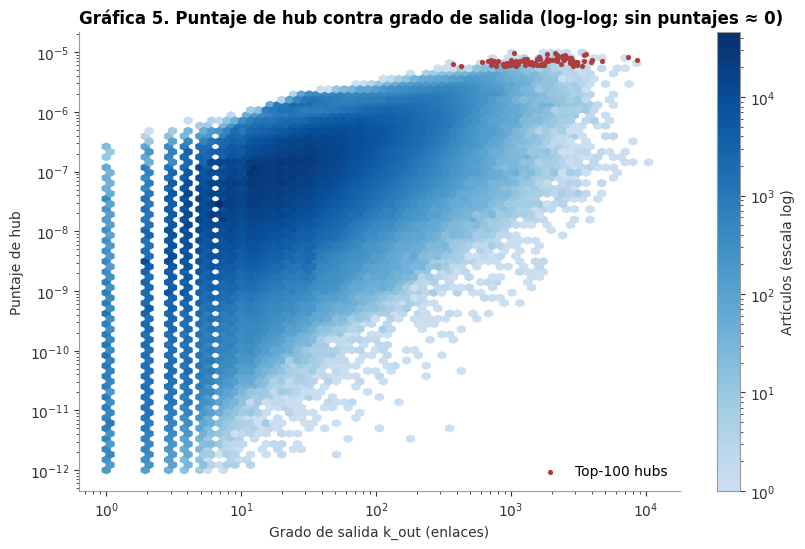

Artículos con hub ≈ 0 (no se grafican): 11,589, de ellos con k_out > 0: 4,032


In [19]:
# Gráfica 5. Puntaje de hub contra grado de salida (log-log)
fig, ax = plt.subplots(figsize=(8.5, 5.6))
con_hub = hubs > CERO
hb = ax.hexbin(k_out_an[con_hub], hubs[con_hub], xscale="log", yscale="log", gridsize=70, bins="log", cmap=CMAP_SEC,
               mincnt=1)
ax.scatter(k_out_an[top_h], hubs[top_h], s=14, color=ROJO, linewidths=0, label="Top-100 hubs")
fig.colorbar(hb, ax=ax, label="Artículos (escala log)")
estilo_ejes(ax, "Gráfica 5. Puntaje de hub contra grado de salida (log-log; sin puntajes ≈ 0)",
            "Grado de salida k_out (enlaces)", "Puntaje de hub", rejilla=None)
ax.legend(loc="lower right")
plt.tight_layout()
archivo_g5 = reg.guardar_figura(fig, "grafica_05_hub_vs_kout", NB)
plt.show()
print(f"Artículos con hub ≈ 0 (no se grafican): {(~con_hub).sum():,}, de ellos con k_out > 0: "
      f"{((~con_hub) & (k_out_an > 0)).sum():,}")
reg.registrar_paso("02.5.2", inicio, [reg.guardar_tabla(tabla_aut, "05_2_top_autoridades", NB),
                                      reg.guardar_tabla(tabla_hubs, "05_2_top_hubs", NB),
                                      reg.guardar_tabla(marcas_top, "05_2_listas_y_cronologias", NB), archivo_g5],
                   f"autoridad 1: {tabla_aut.iloc[0, 0]}; hub 1: {tabla_hubs.iloc[0, 0]}")

**Observaciones: hubs y autoridades**

- **Las autoridades son el núcleo general, con un sesgo estadounidense.** Las primeras son *The New York Times*,
  *United States*, *World War II*, *New York City*, *U.S. state* y *The Guardian*. Después aparecen
  *United States Census Bureau*, *Geographic Names Information System*, *2020 United States census*,
  *Federal Information Processing Standards*, *ZIP Code* y *Race and ethnicity in the United States census*. Son las
  fuentes que cita cada uno de los decenas de miles de artículos de pueblos y condados de Estados Unidos.
  Coinciden en parte con el grado de entrada: Spearman $\rho$(autoridad, $k_{in}$) = **0.8730** y Jaccard del
  top-100 = **0.471**.
- **Los hubs son listas y cronologías.** En el top-100 de hubs hay **55** listas y **30** páginas de año o
  cronología, cuando al azar se esperarían 1.9 y 0.5. Ejemplos: *Demonym*, *2025 in the United States*,
  *List of University of Pennsylvania people*, *May 1982*, *2020s*, *List of enclaves and exclaves*, *21st century*.
  **Ninguna** lista o cronología está en el top-100 de autoridades.
- **Los mejores hubs no son los de más enlaces (Gráfica 5).** Su lugar por $k_{out}$ va del **6** al **3,125**. El
  Jaccard del top-100 de hubs con el top por $k_{out}$ es de apenas **0.031**, y $\rho$(hub, $k_{out}$) =
  **0.5714**. Un buen hub no es el que más enlaza, sino el que enlaza a las autoridades: países, Estados Unidos y
  las grandes fuentes. Las listas más largas (de aves, de municipios italianos) enlazan a artículos poco enlazados.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · HITS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5.3 Efecto TKC: ¿qué comunidad se lleva el peso?</span></div>


El **efecto TKC** (*Tightly Knit Community*; Lempel y Moran, 2000): una comunidad densa, en la que muchos hubs enlazan
a las mismas autoridades, se lleva casi todo el peso de HITS aunque no sea la más relevante. Se mide la densidad del
bloque top-hubs → top-autoridades y se revisan las **categorías** más frecuentes de las autoridades principales para
ver de qué comunidad son.

In [20]:
# Densidad del bloque top-hubs → top-autoridades y categorías de las top-autoridades
inicio = time.time()
bloque_ha = A_an[top_h][:, top_a]
densidad_global = A_an.nnz / n_an ** 2
top_h1000 = np.argsort(-hubs)[:1000]
recibidos = A_an[:, top_a]
desde_hubs = recibidos[top_h1000].nnz
print(f"Densidad del bloque top-100 hubs → top-100 autoridades: {bloque_ha.nnz / 100 ** 2:.4f} "
      f"(grafo: {densidad_global:.2e}; {bloque_ha.nnz / 100 ** 2 / densidad_global:,.0f} veces mayor)")
print(f"Enlaces que reciben las top-100 autoridades: {recibidos.nnz:,} | desde los top-1,000 hubs: {desde_hubs:,} "
      f"({pct(desde_hubs / recibidos.nnz)}), aunque son el {pct(1000 / n_an, 4)} de los artículos")

ids_top_a = nodos_an.loc[top_a, "id"].to_numpy()
cats_top = (ds.dataset(GRAFO / "categorias_nodo").to_table(filter=ds.field("id").isin(ids_top_a)).to_pandas())
# Sin categorías de mantenimiento («Articles containing…», «Pages with…», «Use dmy dates…»), que no describen el tema
MANTENIMIENTO = r"^(Wikipedia|Articles?\b|All articles|Pages?\b|CS1|Webarchive|Use |Short description|Commons|Good articles|Featured |Coordinates)"
cats_top = cats_top[~cats_top["category"].str.match(MANTENIMIENTO)]
print("Categorías más frecuentes entre las top-100 autoridades (sin categorías de mantenimiento):")
categorias_top = cats_top["category"].value_counts().head(20).rename("autoridades del top-100").to_frame()
display(categorias_top.head(12))
tabla_tkc = pd.Series({"densidad bloque top-100 hubs → top-100 autoridades": bloque_ha.nnz / 100 ** 2,
                       "densidad del grafo": densidad_global,
                       "enlaces que reciben las top-100 autoridades": recibidos.nnz,
                       "de ellos desde los top-1,000 hubs": desde_hubs}, name="valor").to_frame()
reg.registrar_paso("02.5.3", inicio, [reg.guardar_tabla(tabla_tkc, "05_3_tkc", NB),
                                      reg.guardar_tabla(categorias_top, "05_3_categorias_top_autoridades", NB)],
                   f"densidad del bloque {bloque_ha.nnz / 100 ** 2:.4f}")

Densidad del bloque top-100 hubs → top-100 autoridades: 0.3581 (grafo: 4.93e-06; 72,666 veces mayor)
Enlaces que reciben las top-100 autoridades: 6,564,244 | desde los top-1,000 hubs: 27,253 (0.42 %), aunque son el 0.0145 % de los artículos


Categorías más frecuentes entre las top-100 autoridades (sin categorías de mantenimiento):


,autoridades del top-100
category,
Member states of the United Nations,21
OECD members,14
G20 members,14
Countries in Europe,12
Member states of NATO,12
Member states of the Council of Europe,9
Member states of the European Union,8
Member states of the Union for the Mediterranean,8
Podcasting companies,7


**Observaciones: efecto TKC**

- **El bloque de hubs y autoridades es muy denso.** El **35.81 %** de los enlaces posibles entre el top-100 de hubs y
  el top-100 de autoridades existe: **72,666 veces** la densidad del grafo (**4.93e-06**).
- **La comunidad que se lleva el peso es el núcleo de referencia general.** Las categorías más frecuentes de las
  top-100 autoridades son *Member states of the United Nations* (**21**), *OECD members* (**14**), *G20 members*
  (**14**), *Countries in Europe* y *Member states of NATO* (**12** cada una). Son los países, Estados Unidos y sus
  instituciones estadísticas, y los grandes medios.
- **El peso viene de la estructura, no del volumen.** Las top-100 autoridades reciben **6,564,244** enlaces, y solo
  **27,253** (**0.42 %**) vienen de los top-1,000 hubs. HITS no premia a quien recibe más enlaces, sino a quien
  recibe enlaces de páginas que enlazan a la vez a las demás autoridades.
- **A diferencia de cit-HepPh y Spotify**, la comunidad dominante no es un nicho (una subárea de física, el clúster
  de música clásica), sino el centro temático de Wikipedia. Por eso el efecto TKC aquí no aleja a HITS de PageRank
  (sección 5.4).

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · HITS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5.4 PageRank contra HITS</span></div>


PageRank y las autoridades de HITS miden "importancia por enlaces", pero de forma distinta:

- PageRank reparte el puntaje de cada artículo entre sus enlaces y se teletransporta, así que es **global**.
- HITS refuerza a la vez hubs y autoridades sin teletransportación, así que se queda con la **estructura dominante**
  de $A^\top A$.

,PageRank vs autoridad
Jaccard top-20,0.333
Jaccard top-100,0.449
"Jaccard top-1,000",0.461
Spearman ρ (todos),0.7680
Kendall τ (todos),0.5815
Spearman ρ (solo autoridad > 0),0.7369


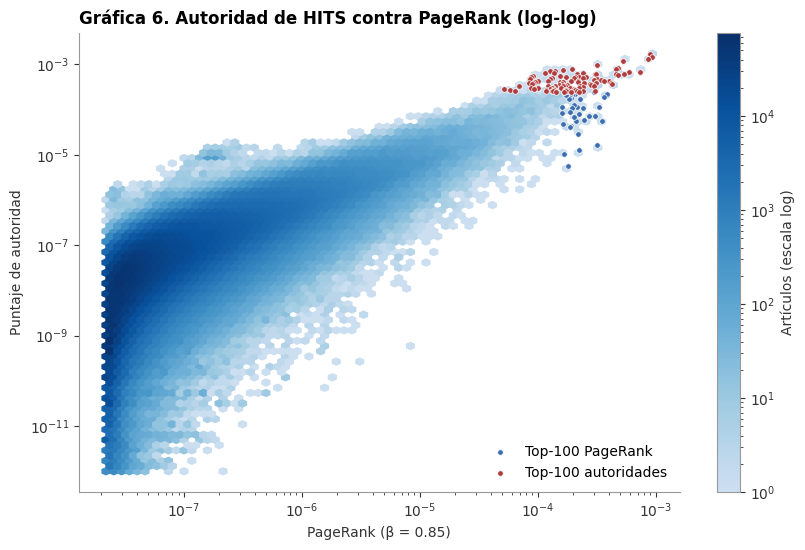

Del top-100 de PageRank, también en el top-100 de autoridades: 62


In [21]:
# Comparación PageRank vs autoridades: traslape, correlación de rangos y Gráfica 6
inicio = time.time()
comparacion_pr_hits = pd.Series({
    "Jaccard top-20": f"{jaccard_top(pr85, autoridades, 20):.3f}",
    "Jaccard top-100": f"{jaccard_top(pr85, autoridades, 100):.3f}",
    "Jaccard top-1,000": f"{jaccard_top(pr85, autoridades, 1000):.3f}",
    "Spearman ρ (todos)": f"{spearmanr(pr85, autoridades).statistic:.4f}",
    "Kendall τ (todos)": f"{kendalltau(pr85, autoridades).statistic:.4f}",
    "Spearman ρ (solo autoridad > 0)": f"{spearmanr(pr85[autoridades > CERO], autoridades[autoridades > CERO]).statistic:.4f}",
}, name="PageRank vs autoridad").to_frame()
display(comparacion_pr_hits)

fig, ax = plt.subplots(figsize=(8.5, 5.6))
con_aut = autoridades > CERO
hb = ax.hexbin(pr85[con_aut], autoridades[con_aut], xscale="log", yscale="log", gridsize=70, bins="log", cmap=CMAP_SEC,
               mincnt=1)
top_pr = np.argsort(-pr85)[:100]
ax.scatter(pr85[top_pr], np.clip(autoridades[top_pr], CERO, None), s=16, color=AZUL, edgecolors="white", linewidths=0.5,
           label="Top-100 PageRank")
ax.scatter(pr85[top_a], autoridades[top_a], s=16, color=ROJO, edgecolors="white", linewidths=0.5,
           label="Top-100 autoridades")
fig.colorbar(hb, ax=ax, label="Artículos (escala log)")
estilo_ejes(ax, "Gráfica 6. Autoridad de HITS contra PageRank (log-log)", "PageRank (β = 0.85)", "Puntaje de autoridad",
            rejilla=None)
ax.legend(loc="lower right")
plt.tight_layout()
archivo_g6 = reg.guardar_figura(fig, "grafica_06_autoridad_vs_pagerank", NB)
plt.show()
print(f"Del top-100 de PageRank, también en el top-100 de autoridades: {len(np.intersect1d(top_pr, top_a))}")
reg.registrar_paso("02.5.4", inicio, [reg.guardar_tabla(comparacion_pr_hits, "05_4_pagerank_vs_autoridades", NB), archivo_g6],
                   f"Spearman {comparacion_pr_hits.iloc[3, 0]}; Jaccard top-100 {comparacion_pr_hits.iloc[1, 0]}")

**Observaciones: PageRank contra HITS**

- **En Wikipedia, PageRank y las autoridades de HITS coinciden bastante.** **62** del top-100 de PageRank están en el
  top-100 de autoridades. El Jaccard es de **0.333** en el top-20, **0.449** en el top-100 y **0.461** en el
  top-1,000. La correlación de rangos es Spearman **0.7680** y Kendall **0.5815**. En cit-HepPh el Jaccard del
  top-100 era de 0.053, porque las autoridades eran una comunidad aparte.
- **Dónde difieren (Gráfica 6).**
  - Las autoridades favorecen al bloque de geografía estadounidense: *United States Census Bureau*, *GNIS*,
    *FIPS*, *ZIP Code*.
  - PageRank favorece a artículos muy enlazados desde fuera de ese bloque: *Moth*, *Latin*,
    *Oxford University Press*, *Catholic Church*.
- **Por qué.** La estructura dominante de $A^\top A$ en Wikipedia es el propio núcleo general, el mismo al que
  PageRank lleva la probabilidad. Los dos métodos miran casi lo mismo, y la diferencia la marcan los bloques densos
  de artículos que se citan en cadena, como el de los pueblos de Estados Unidos.

In [22]:
# Guardado de los puntajes para el notebook 3: PageRank (β = 0.85), hubs y autoridades del grafo de análisis
puntajes = pd.DataFrame({"id": nodos_an["id"], "pagerank": pr85, "hub": hubs, "autoridad": autoridades})
puntajes.to_parquet(ARCHIVO_PUNTAJES, index=False)
print(f"{ARCHIVO_PUNTAJES.name}: {len(puntajes):,} filas, {tamano(ARCHIVO_PUNTAJES.stat().st_size)}")

puntajes.parquet: 6,879,374 filas, 193.9 MB


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · EXTRAS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6. Análisis adicionales</span></div>


Las secciones anteriores son el análisis principal. Estas cuatro lo complementan y se ejecutan una a la vez, en este
orden, cada una con sus propios resultados guardados:

1. **6.1** Valores singulares de $A$ con `svds`, para confirmar HITS de forma independiente.
2. **6.2** Robustez de PageRank con y sin páginas de desambiguación.
3. **6.3** Sesgo por antigüedad, con el `page_id` como proxy.
4. **6.4** HITS dependiente de una consulta.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · EXTRAS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6.1 Valores singulares con svds</span></div>


Se calculan los tres primeros valores singulares de $A$ con `svds` (ARPACK), sin usar los vectores de HITS, con
`maxiter = 30`. Si HITS convergió al vector singular principal, el cociente de Rayleigh de la sección 5.1 debe ser
igual a $\sigma_1^2$. La brecha $\sigma_1 / \sigma_2$ explica la velocidad: el error de HITS se reduce por un factor
$(\sigma_2 / \sigma_1)^2$ por iteración, así que con tolerancia $10^{-10}$ se esperan unas
$\log 10^{-10} / \log (\sigma_2/\sigma_1)^2$ iteraciones.

In [23]:
# Valores singulares principales de A con svds (maxiter = 30) y comparación con el cociente de Rayleigh
inicio = time.time()
from scipy.sparse.linalg import ArpackNoConvergence

t0 = time.perf_counter()
try:
    sigmas = np.sort(svds(A_an, k=3, return_singular_vectors=False, maxiter=30, random_state=42))[::-1]
    estado_svds = "convergió"
except ArpackNoConvergence as error:
    # Valores propios parciales de AᵀA que alcanzó ARPACK
    parciales = np.sort(np.sqrt(np.abs(np.asarray(error.eigenvalues, dtype=float))))[::-1]
    sigmas = np.concatenate([parciales, np.full(3 - len(parciales), np.nan)])[:3]
    estado_svds = f"no convergió con maxiter = 30 ({len(parciales)} valores parciales)"
    reg.nota(f"svds (k = 3, maxiter = 30) no convergió; valores singulares parciales: {np.round(parciales, 2).tolist()}")
segundos_svds = time.perf_counter() - t0

tasa = (sigmas[1] / sigmas[0]) ** 2
tabla_svds = pd.Series({
    "estado": estado_svds,
    "σ₁, σ₂, σ₃": ", ".join(f"{s:,.2f}" for s in sigmas),
    "σ₁² (de svds)": f"{sigmas[0] ** 2:,.2f}",
    "λ (cociente de Rayleigh de HITS)": f"{rayleigh:,.2f}",
    "diferencia relativa λ / σ₁² − 1": f"{rayleigh / sigmas[0] ** 2 - 1:.2e}",
    "brecha σ₁ / σ₂": f"{sigmas[0] / sigmas[1]:.4f}",
    "reducción del error por iteración (σ₂/σ₁)²": f"{tasa:.4f}",
    "iteraciones esperadas para 10⁻¹⁰": f"{np.log(1e-10) / np.log(tasa):.0f}",
    "iteraciones observadas de HITS": f"{it_hits}",
    "tiempo de svds": f"{segundos_svds:.0f} s",
}, name="Valor").rename_axis("svds").to_frame()
display(tabla_svds)
reg.registrar_paso("02.E1", inicio, [reg.guardar_tabla(tabla_svds, "06_1_svds", NB)], estado_svds)

,Valor
svds,
estado,convergió
"σ₁, σ₂, σ₃","762.66, 696.12, 627.39"
σ₁² (de svds),"581,653.65"
λ (cociente de Rayleigh de HITS),"581,653.65"
diferencia relativa λ / σ₁² − 1,-2.86e-13
brecha σ₁ / σ₂,1.0956
reducción del error por iteración (σ₂/σ₁)²,0.8331
iteraciones esperadas para 10⁻¹⁰,126
iteraciones observadas de HITS,106


**Observaciones: valores singulares**

- **`svds` convergió con `maxiter = 30`** en **115** s: $\sigma_1, \sigma_2, \sigma_3$ = **762.66**, **696.12** y
  **627.39**.
- **HITS llegó al vector singular principal.** $\sigma_1^2$ = **581,653.65**, igual al cociente de Rayleigh de la
  sección 5.1, con una diferencia relativa de **−2.86e-13**.
- **La brecha es pequeña.** $\sigma_1 / \sigma_2$ = **1.0956**, así que el error se reduce por un factor
  $(\sigma_2/\sigma_1)^2$ = **0.8331** en cada iteración. Para $10^{-10}$ se esperarían **126** iteraciones y HITS
  usó **106**: la cota es algo pesimista porque el vector inicial ya tiene más peso en la dirección principal.
- **Varias estructuras de peso parecido.** Una brecha tan pequeña indica que hay varios bloques densos casi tan
  fuertes como el principal, igual que en cit-HepPh (1.0762).

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · EXTRAS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6.2 Robustez: con y sin páginas de desambiguación</span></div>


Se recalcula PageRank ($\beta = 0.85$) sobre el **grafo completo**, con las páginas de desambiguación, y se
compara con el ranking principal sobre los artículos que están en los dos grafos.

In [24]:
# PageRank sobre el grafo completo y comparación con el grafo de análisis
inicio = time.time()
pr_completo, it_completo = pagerank_potencia(AT_bloques, inv_k_out, beta=0.85)
comun = pr_completo[conserva]   # mismos artículos, en el orden del grafo de análisis
robustez = pd.Series({
    "Iteraciones (completo / análisis)": f"{it_completo} / {filas_pr[1]['iteraciones']}",
    "Masa de PageRank en desambiguaciones (completo)": pct(pr_completo[~conserva].sum()),
    "Desambiguaciones en el top-100 / top-1,000 del completo": f"{(~conserva[np.argsort(-pr_completo)[:100]]).sum()} / "
                                                               f"{(~conserva[np.argsort(-pr_completo)[:1000]]).sum()}",
    "Jaccard top-20": f"{jaccard_top(comun, pr85, 20):.3f}",
    "Jaccard top-100": f"{jaccard_top(comun, pr85, 100):.3f}",
    "Jaccard top-1,000": f"{jaccard_top(comun, pr85, 1000):.3f}",
    "Spearman ρ (artículos comunes)": f"{spearmanr(comun, pr85).statistic:.4f}",
    "Kendall τ (artículos comunes)": f"{kendalltau(comun, pr85).statistic:.4f}",
}, name="Valor").rename_axis("PageRank β = 0.85").to_frame()
display(robustez)

cambio = pr85 / (comun / comun.sum()) - 1
casos = pd.DataFrame({"artículo": nodos_an["title"], "k_in": k_in_an, "lugar análisis": lugar_pr,
                      "lugar completo": pd.Series(comun).rank(ascending=False, method="min").astype(int).to_numpy(),
                      "cambio de puntaje": cambio})
print("Del top-1,000 del grafo de análisis, los que más cambian al quitar las desambiguaciones:")
mas_cambian = casos[casos["lugar análisis"] <= 1000].reindex(
    casos.loc[casos["lugar análisis"] <= 1000, "cambio de puntaje"].abs().nlargest(10).index)
display(mas_cambian.head(6).style.format({"cambio de puntaje": "{:+.1%}", "k_in": "{:,}"}))
vector_completo = pd.DataFrame({"id": nodos["id"], "title": nodos["title"], "is_disambig": nodos["is_disambig"],
                                "pagerank_completo": pr_completo})
reg.registrar_paso("02.E2", inicio, [reg.guardar_tabla(robustez, "06_2_robustez", NB),
                                     reg.guardar_tabla(mas_cambian, "06_2_mas_cambian", NB),
                                     reg.guardar_parquet(vector_completo, "06_2_pagerank_grafo_completo", NB)],
                   f"Spearman {robustez.loc['Spearman ρ (artículos comunes)', 'Valor']}")
del AT_bloques   # el grafo completo ya no se usa

,Valor
PageRank β = 0.85,
Iteraciones (completo / análisis),70 / 70
Masa de PageRank en desambiguaciones (completo),0.84 %
"Desambiguaciones en el top-100 / top-1,000 del completo",0 / 0
Jaccard top-20,1.000
Jaccard top-100,0.961
"Jaccard top-1,000",0.986
Spearman ρ (artículos comunes),0.9920
Kendall τ (artículos comunes),0.9561


Del top-1,000 del grafo de análisis, los que más cambian al quitar las desambiguaciones:


,artículo,k_in,lugar análisis,lugar completo,cambio de puntaje
indice,,,,,
4082500,Dehestan (administrative division),"51,176.0",240,222,-5.8%
987948,Bakhsh,"54,835.0",121,106,-5.5%
1156209,Counties of Iran,"55,035.0",119,100,-5.5%
171465,Provinces of Iran,"55,136.0",117,98,-5.5%
970998,Iran Standard Time,"55,216.0",127,118,-5.4%
90858,Romanization,"47,318.0",216,203,-5.3%


**Observaciones: robustez**

- **PageRank es robusto a la exclusión de las desambiguaciones.** Sobre los artículos comunes: Spearman **0.9920**,
  Kendall **0.9561**, Jaccard del top-20 **1.000**, del top-100 **0.961** y del top-1,000 **0.986**. Los dos grafos
  convergen en **70** iteraciones.
- **Las desambiguaciones casi no tienen peso.** En el grafo completo acumulan el **0.84 %** del PageRank y
  **ninguna** entra al top-1,000: casi nadie las enlaza.
- **Lo que más cambia es poco y tiene explicación.** Los mayores cambios del top-1,000 van de **−5.8 %** a
  **−5.3 %**. Les tocan a *Dehestan (administrative division)*, *Bakhsh*, *Counties of Iran*, *Provinces of Iran*,
  *Iran Standard Time* y *Romanization*. Hay decenas de miles de artículos de aldeas iraníes con nombres repetidos,
  y las desambiguaciones que los listan alimentaban un poco el flujo hacia estos artículos.
- **Decisión.** Excluir las desambiguaciones no cambia las conclusiones y deja un grafo más limpio, así que se
  mantiene.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · EXTRAS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6.3 ¿Sesgo por antigüedad?</span></div>


En cit-HepPh las citas apuntan casi siempre al pasado y PageRank favorecía a los artículos viejos. En Wikipedia no
hay fechas de creación en el dump, pero el `page_id` crece con el orden de creación (notebook 1, sección 3), y la
Gráfica 1 muestra que el **73 %** de los enlaces apunta a un `page_id` menor. Se revisa si PageRank se concentra en
los `page_id` bajos, dividiendo los artículos en **deciles de `page_id`**.

**Advertencia:** el `page_id` es solo un proxy de la antigüedad. Además, los artículos más antiguos suelen ser los
temas más generales (países, ciudades, guerras), así que un sesgo aquí no separa "edad" de "generalidad del tema".

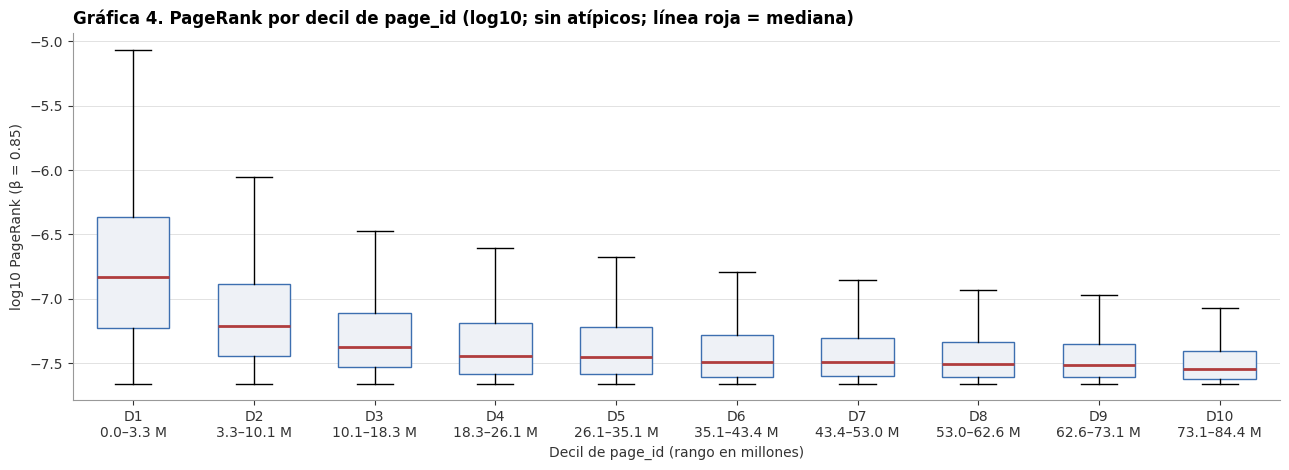

,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
artículos,687938,687937,687937,687938,687937,687937,687938,687937,687937,687938
PageRank mediano,1.47e-07,6.18e-08,4.23e-08,3.61e-08,3.53e-08,3.21e-08,3.23e-08,3.13e-08,3.07e-08,2.85e-08
% del PageRank total,51.6 %,11.4 %,6.7 %,7.2 %,5.2 %,4.3 %,3.9 %,3.5 %,3.3 %,2.9 %
en el top-100,74,12,3,10,0,0,0,0,1,0
"en el top-10,000",8305,475,212,597,176,104,63,27,22,19


Spearman ρ(PageRank, page_id) = -0.4063


In [25]:
# Gráfica 4. PageRank por decil de page_id
inicio = time.time()
decil = pd.qcut(nodos_an["id"], 10, labels=False).to_numpy()
limites = nodos_an.groupby(decil)["id"].agg(["min", "max"])
etiquetas = [f"D{d + 1}\n{limites.loc[d, 'min'] / 1e6:.1f}–{limites.loc[d, 'max'] / 1e6:.1f} M" for d in range(10)]

fig, ax = plt.subplots(figsize=(13, 4.8))
caja = ax.boxplot([np.log10(pr85[decil == d]) for d in range(10)], positions=range(10), widths=0.6,
                  patch_artist=True, showfliers=False, medianprops=dict(color=ROJO, linewidth=2))
for parche in caja["boxes"]:
    parche.set(facecolor=GRIS_CLARO, edgecolor=AZUL)
ax.set_xticks(range(10), labels=etiquetas)
estilo_ejes(ax, "Gráfica 4. PageRank por decil de page_id (log10; sin atípicos; línea roja = mediana)",
            "Decil de page_id (rango en millones)", "log10 PageRank (β = 0.85)")
plt.tight_layout()
archivo_g4 = reg.guardar_figura(fig, "grafica_04_pagerank_por_decil", NB)
plt.show()

top100 = np.argsort(-pr85)[:100]
por_decil = pd.DataFrame({
    "artículos": pd.Series(decil).value_counts().sort_index(),
    "PageRank mediano": pd.Series(pr85).groupby(decil).median().map(lambda x: f"{x:.2e}"),
    "% del PageRank total": pd.Series(pr85).groupby(decil).sum().map(lambda x: pct(x, 1)),
    "en el top-100": pd.Series(decil[top100]).value_counts().reindex(range(10), fill_value=0),
    "en el top-10,000": pd.Series(decil[np.argsort(-pr85)[:10_000]]).value_counts().reindex(range(10), fill_value=0),
})
por_decil.index = [f"D{d + 1}" for d in range(10)]
display(por_decil.T)
rho_id = spearmanr(pr85, nodos_an["id"]).statistic
print(f"Spearman ρ(PageRank, page_id) = {rho_id:.4f}")
reg.registrar_paso("02.E3", inicio, [archivo_g4, reg.guardar_tabla(por_decil, "06_3_pagerank_por_decil", NB)],
                   f"Spearman ρ(PageRank, page_id) = {rho_id:.4f}")

**Observaciones: sesgo por antigüedad**

- **PageRank se concentra en los `page_id` más bajos (Gráfica 4).** El primer decil (D1) tiene el **51.6 %** del
  PageRank total, **74** del top-100 y **8,305** del top-10,000. El PageRank mediano baja de **1.47e-07** (D1) a
  **2.85e-08** (D10), y $\rho$(PageRank, `page_id`) = **−0.4063**.
- **No es del todo monótono.** D4 tiene **10** del top-100 y **597** del top-10,000, más que D2 y D3.
- **No se puede separar la edad del tema.** Los artículos más antiguos son los temas más generales (países,
  ciudades, guerras), y el 73 % de los enlaces apunta a un `page_id` menor (Gráfica 1). Además, un artículo nuevo ha
  tenido menos tiempo para que lo enlacen. Sin fechas de creación, este análisis solo muestra que el sesgo existe,
  no cuánto se debe a cada causa.
- **Diferencia con cit-HepPh.** Allí no había citas al futuro, así que el ajuste por cohorte tenía sentido. Aquí un
  artículo de 2002 sigue recibiendo enlaces en 2026, así que no hay "cohortes completas" que comparar.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · EXTRAS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6.4 HITS dependiente de una consulta</span></div>


En la formulación original, HITS **no se calcula sobre toda la Web**, sino sobre un subgrafo ligado a una consulta
(Kleinberg, 1999):

1. **Conjunto raíz** $R$: las páginas que responden a la consulta. Aquí, los artículos de una categoría de Wikipedia
   y de sus subcategorías hasta 2 niveles.
2. **Conjunto base** $S$: $R$ más los artículos a los que enlaza $R$ y, por cada artículo de $R$, hasta $d = 50$ de
   los que lo enlazan (elegidos al azar con semilla 42, para que un artículo muy enlazado no meta a medio grafo).
3. HITS sobre el subgrafo inducido por $S$.

Así se evita el efecto TKC global (5.3): las autoridades son las de **ese tema**. Se aplica a dos consultas de temas
muy distintos.

In [26]:
# Conjunto raíz desde el árbol de categorías y HITS sobre el conjunto base
inicio = time.time()
jerarquia = pq.read_table(GRAFO / "jerarquia_categorias").to_pandas()
hijas_de = jerarquia.groupby("padre")["categoria"].apply(list).to_dict()
posicion_an = np.full(ids.max() + 1, -1, dtype=np.int64)
posicion_an[nodos_an["id"].to_numpy()] = np.arange(n_an)
A_an_csc = A_an.tocsc()


def hits_consulta(categoria, niveles=2, d=50, semilla=42, k=10):
    """
    HITS de Kleinberg sobre el conjunto base de una categoría.

    Parámetros
    ----------
    categoria : str
        Categoría raíz de la consulta (sin el prefijo «Category:»).
    niveles : int
        Profundidad de subcategorías que se incluyen en el conjunto raíz.
    d : int
        Máximo de artículos que enlazan a cada artículo del conjunto raíz que entran al conjunto base.
    semilla : int
        Semilla para elegir esos d artículos.
    k : int
        Tamaño de las tablas que se devuelven.

    Retorna
    -------
    tuple of (pd.Series, pd.DataFrame, pd.DataFrame)
        Tamaños de los conjuntos y top-k de autoridades y de hubs.
    """
    rng = np.random.default_rng(semilla)
    categorias, frontera = {categoria}, [categoria]
    for _ in range(niveles):
        frontera = [h for c in frontera for h in hijas_de.get(c, []) if h not in categorias]
        categorias.update(frontera)
    ids_raiz = ds.dataset(GRAFO / "categorias_nodo").to_table(filter=ds.field("category").isin(list(categorias)),
                                                               columns=["id"]).column("id").to_numpy()
    raiz = np.unique(posicion_an[ids_raiz])
    raiz = raiz[raiz >= 0]
    if len(raiz) == 0:
        raise ValueError(f"La categoría {categoria!r} no tiene artículos en el grafo de análisis")
    salida = A_an[raiz].indices
    entrada = []
    for j in raiz:
        quienes = A_an_csc.indices[A_an_csc.indptr[j]:A_an_csc.indptr[j + 1]]
        entrada.append(quienes if len(quienes) <= d else rng.choice(quienes, d, replace=False))
    base = np.unique(np.concatenate([raiz, salida, *entrada]))
    sub = A_an[base][:, base].tocsr()
    h, a, iteraciones = hits_potencia([sub], [sub.T.tocsr()], tol=1e-12)
    en_raiz = np.isin(base, raiz)

    def tabla(puntaje):
        orden = np.argsort(-puntaje)[:k]
        return pd.DataFrame({"artículo": nodos_an.loc[base[orden], "title"].to_numpy(), "puntaje": puntaje[orden],
                             "en el conjunto raíz": np.where(en_raiz[orden], "sí", "no"),
                             "lugar global en PageRank": lugar_pr[base[orden]]},
                            index=pd.RangeIndex(1, k + 1, name="lugar"))

    tamanos = pd.Series({"categorías": len(categorias), "conjunto raíz R": len(raiz), "conjunto base S": len(base),
                         "aristas en S": sub.nnz, "iteraciones de HITS": iteraciones}, name=categoria)
    return tamanos, tabla(a), tabla(h)


CONSULTAS = ["Machine learning", "Mexican cuisine"]
archivos_consulta, filas_tamanos = [], []
for consulta in CONSULTAS:
    tamanos, top_aut, top_hub = hits_consulta(consulta)
    filas_tamanos.append(tamanos)
    nombre = consulta.lower().replace(" ", "_")
    archivos_consulta += [reg.guardar_tabla(top_aut, f"06_4_autoridades_{nombre}", NB),
                          reg.guardar_tabla(top_hub, f"06_4_hubs_{nombre}", NB)]
    print(f"Consulta: {consulta} | " + " | ".join(f"{k}: {v:,}" for k, v in tamanos.items()))
    print("Autoridades:")
    display(top_aut.style.format({"puntaje": "{:.4f}", "lugar global en PageRank": "{:,}"}))
    print("Hubs:")
    display(top_hub.style.format({"puntaje": "{:.4f}", "lugar global en PageRank": "{:,}"}))
archivos_consulta.append(reg.guardar_tabla(pd.DataFrame(filas_tamanos), "06_4_tamanos_conjuntos", NB))
reg.registrar_paso("02.E4", inicio, archivos_consulta, ", ".join(CONSULTAS))

Consulta: Machine learning | categorías: 64 | conjunto raíz R: 1,929 | conjunto base S: 28,165 | aristas en S: 950,036 | iteraciones de HITS: 39
Autoridades:


,artículo,puntaje,en el conjunto raíz,lugar global en PageRank
lugar,,,,
1,The New York Times,0.0056,no,2
2,The Guardian,0.0037,no,8
3,The Washington Post,0.0033,no,29
4,Artificial intelligence,0.0030,no,465
5,The Wall Street Journal,0.0028,no,81
6,Reuters,0.0027,no,76
7,CNN,0.0026,no,118
8,BBC News,0.0024,no,45
9,United States,0.0023,no,1


Hubs:


,artículo,puntaje,en el conjunto raíz,lugar global en PageRank
lugar,,,,
1,2025 in the United States,0.0007,no,"1,173,823"
2,2020s,0.0006,no,"676,894"
3,List of University of Pennsylvania people,0.0006,no,"1,861,906"
4,21st century,0.0006,no,"208,540"
5,Google,0.0006,no,494
6,2026 in the United States,0.0006,no,"2,393,619"
7,United States,0.0005,no,1
8,List of Vanderbilt University people,0.0005,no,"1,804,969"
9,TikTok,0.0005,no,"2,779"


Consulta: Mexican cuisine | categorías: 73 | conjunto raíz R: 1,048 | conjunto base S: 23,120 | aristas en S: 762,290 | iteraciones de HITS: 34
Autoridades:


,artículo,puntaje,en el conjunto raíz,lugar global en PageRank
lugar,,,,
1,The New York Times,0.0036,no,2
2,United States,0.0032,no,1
3,World War II,0.0028,no,3
4,Mexico,0.0022,no,63
5,The Guardian,0.0021,no,8
6,Catholic Church,0.0021,no,13
7,China,0.0018,no,14
8,New York City,0.0017,no,7
9,United Kingdom,0.0017,no,6


Hubs:


,artículo,puntaje,en el conjunto raíz,lugar global en PageRank
lugar,,,,
1,American cuisine,0.0007,no,"30,619"
2,List of snack foods,0.0007,no,"810,171"
3,2020s,0.0006,no,"676,894"
4,List of soups,0.0006,no,"106,179"
5,21st century,0.0006,no,"208,540"
6,United States,0.0006,no,1
7,List of stews,0.0006,no,"148,223"
8,Hispanic and Latino Americans,0.0005,no,234
9,National dish,0.0005,no,"50,464"


**Observaciones: HITS dependiente de una consulta**

- **Los conjuntos.** Para *Machine learning* (2 niveles, **64** categorías), el conjunto raíz tiene **1,929**
  artículos y el conjunto base **28,165**, con **950,036** aristas. HITS converge en **39** iteraciones. Para
  *Mexican cuisine* (**73** categorías): **1,048** → **23,120** artículos, **762,290** aristas y **34**
  iteraciones.
- **Hay deriva temática (*topic drift*).** **Ninguna** de las 10 primeras autoridades está en el conjunto raíz.
  - En *Machine learning* las autoridades son medios (*The New York Times*, *The Guardian*,
    *The Washington Post*, *Reuters*, *CNN*). Solo *Artificial intelligence* (4.º) es del tema.
  - En *Mexican cuisine* son *The New York Times*, *United States*, *World War II*, *Mexico* (4.º) y
    *The Guardian*.
  - Los hubs son páginas de año (*2025 in the United States*, *2020s*, *21st century*) y listas.
- **Por qué.** Al agregar hasta 50 artículos que enlazan a cada artículo raíz entran páginas generales que enlazan a
  todo, y los artículos raíz enlazan a los medios que citan. Dentro del conjunto base reaparece el mismo núcleo
  general que domina el HITS global (5.3). Kleinberg ya describía este problema.
- **Hay señal del tema en los hubs.** En *Mexican cuisine* aparecen *American cuisine*, *List of snack foods*,
  *List of soups*, *List of stews* y *National dish*.
- **Cómo se mejoraría.** Hay tres opciones conocidas:
  1. reportar como autoridades solo a los artículos del conjunto raíz;
  2. sacar del conjunto base las páginas de cronología, las listas y los medios;
  3. ponderar las aristas para que muchos enlaces de un mismo sitio cuenten menos (Bharat y Henzinger, 1998).

In [27]:
POOL.shutdown()

> Las conclusiones y limitaciones de la práctica completa están al final de `03_topic_sensitive.ipynb`.